# InterviewSense — Communication Assessment Model
## Stage 2: Supervised Speaking-Performance Prediction

**Dataset:** `colabsss/multimodal-english-speech-dataset`  
**Primary target:** `overall_score` (regression)  
**Secondary target:** `target_level` (classification)  
**Evaluation:** Speaker-independent 5-fold GroupKFold  
**Models:** Ridge Regression, XGBoost Regression  
**Baseline:** eGeMAPSv02 (opensmile)

---
> **Scientific Scope Note:**  
> This model predicts *measurable English speaking-performance and communication delivery* from acoustic features.  
> It does **NOT** claim to measure intelligence, vocabulary, grammar, semantic relevance, answer correctness, personality, or overall human communication ability.  
> Those require additional linguistic / NLP analysis (transcript-based features — planned in Stage 3).

---
> **NISQA Note:**  
> NISQA was used in Stage 1 as an *acoustic speech-quality baseline*.  
> The new multimodal English speech dataset provides *human-rated speaking-performance labels*, which is a fundamentally different and more relevant target for InterviewSense.


## 01. Environment & Package Setup

In [31]:
import sys
import subprocess
import importlib

REQUIRED_PACKAGES = {
    "kagglehub":        "kagglehub",
    "pandas":           "pandas",
    "numpy":            "numpy",
    "scikit-learn":     "sklearn",
    "librosa":          "librosa",
    "soundfile":        "soundfile",
    "matplotlib":       "matplotlib",
    "seaborn":          "seaborn",
    "xgboost":          "xgboost",
    "opensmile":        "opensmile",
    "joblib":           "joblib",
    "shap":             "shap",
    "tqdm":             "tqdm",
}

print("Checking / installing required packages...")
for pkg_install_name, pkg_import_name in REQUIRED_PACKAGES.items():
    try:
        importlib.import_module(pkg_import_name)
        print(f"  [OK]          {pkg_install_name}")
    except ImportError:
        print(f"  [INSTALLING]  {pkg_install_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", pkg_install_name, "-q"],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL
        )
        print(f"  [DONE]        {pkg_install_name}")

print("\nAll packages ready.")


Checking / installing required packages...
  [OK]          kagglehub
  [OK]          pandas
  [OK]          numpy
  [OK]          scikit-learn
  [OK]          librosa
  [OK]          soundfile
  [OK]          matplotlib
  [OK]          seaborn
  [OK]          xgboost
  [OK]          opensmile
  [OK]          joblib
  [OK]          shap
  [OK]          tqdm

All packages ready.


## 02. Imports

In [32]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
import joblib
import opensmile
import shap

from pathlib import Path
from tqdm import tqdm

# Scikit-learn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# XGBoost
from xgboost import XGBRegressor, XGBClassifier

warnings.filterwarnings("ignore")
np.random.seed(42)

import sklearn
import xgboost as xgb_pkg

print("All imports successful.")
print(f"  numpy   : {np.__version__}")
print(f"  pandas  : {pd.__version__}")
print(f"  sklearn : {sklearn.__version__}")
print(f"  xgboost : {xgb_pkg.__version__}")
print(f"  librosa : {librosa.__version__}")


All imports successful.
  numpy   : 2.4.6
  pandas  : 3.0.5
  sklearn : 1.9.0
  xgboost : 3.2.0
  librosa : 0.11.0


## Global Configuration Constants

All tunable parameters are defined here. Change these values to adjust pipeline behaviour.


In [33]:
# ============================================================
# AUDIO PROCESSING
# ============================================================
TARGET_SR       = 16000   # Target sample rate in Hz
SILENCE_TOP_DB  = 30      # dB threshold below peak for silence detection.
                          # Frames more than SILENCE_TOP_DB dB below the peak
                          # are classified as silence (librosa.effects.split).
                          # Standard values: 20–40 dB.  We use 30 dB.
N_MFCC          = 13      # Number of MFCC coefficients
FMIN_PITCH      = 75.0    # Hz — lower bound of human voice fundamental frequency
FMAX_PITCH      = 400.0   # Hz — upper bound of human voice fundamental frequency

# ============================================================
# DATASET LIMITS
# ============================================================
MAX_SAMPLES     = None    # None = process all matched recordings

# ============================================================
# SPLIT & CROSS-VALIDATION
# ============================================================
TEST_SIZE       = 0.20    # Fraction of speakers held out as final test
N_FOLDS         = 5       # GroupKFold folds on development set
RANDOM_STATE    = 42

# ============================================================
# OUTPUT FILE NAMES
# ============================================================
RAW_FEATURES_CSV     = "communication_features_raw.csv"
CLEAN_FEATURES_CSV   = "communication_features_clean.csv"
CV_RESULTS_CSV       = "group_cross_validation_results.csv"
MODEL_COMPARISON_CSV = "model_comparison_results.csv"
FEATURE_WEIGHTS_CSV  = "primary_feature_weights.csv"
XGB_IMPORTANCE_CSV   = "xgboost_feature_importance.csv"
CLASSIFICATION_CSV   = "classification_results.csv"
FINAL_MODEL_PATH     = "final_model.joblib"
EGEMAPS_CACHE_CSV    = "egemaps_features.csv"

# ============================================================
# COLUMNS THAT MUST NEVER APPEAR AS PREDICTORS (leakage guard)
# ============================================================
FORBIDDEN_PREDICTORS = {
    "pronunciation_score", "fluency_score", "intonation_score",
    "overall_score", "target_level",
    "age", "gender", "region", "education_level", "english_learning_years",
    "sample_id", "speaker_id", "task_type",
    "audio_path", "duration",
}

print("Configuration loaded.")
print(f"  Target SR        : {TARGET_SR} Hz")
print(f"  Silence threshold: {SILENCE_TOP_DB} dB below peak")
print(f"  Pitch range      : {FMIN_PITCH:.0f}–{FMAX_PITCH:.0f} Hz")
print(f"  MFCC coefficients: {N_MFCC}")
print(f"  Test split       : {TEST_SIZE*100:.0f}% of speakers")
print(f"  CV folds         : {N_FOLDS}")


Configuration loaded.
  Target SR        : 16000 Hz
  Silence threshold: 30 dB below peak
  Pitch range      : 75–400 Hz
  MFCC coefficients: 13
  Test split       : 20% of speakers
  CV folds         : 5


## 03. Dataset Download

In [34]:
import kagglehub

print("Downloading dataset (uses Kaggle cache if already present)...")
dataset_path = kagglehub.dataset_download("colabsss/multimodal-english-speech-dataset")
print(f"\nDataset path: {dataset_path}")

# Count all files
all_files = []
for root, dirs, files in os.walk(dataset_path):
    for f in files:
        all_files.append(os.path.join(root, f))

print(f"Number of files: {len(all_files)}")



Dataset path: C:\Users\Mounindra\.cache\kagglehub\datasets\colabsss\multimodal-english-speech-dataset\versions\1
Number of files: 2


## 04. Dataset Directory Inspection

In [35]:
AUDIO_EXTS = {".wav", ".mp3", ".flac", ".ogg", ".m4a", ".opus"}

csv_files   = []
wav_files   = []
mp3_files   = []
flac_files  = []
other_audio = []

print("Directory structure (audio files truncated after 3 per type):\n")

for root, dirs, files in os.walk(dataset_path):
    level  = root.replace(str(dataset_path), "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = "  " * (level + 1)

    for fname in sorted(files):
        full_path = os.path.join(root, fname)
        ext = Path(fname).suffix.lower()

        if ext == ".csv":
            csv_files.append(full_path)
            print(f"{subindent}{fname}  [CSV]")
        elif ext == ".wav":
            if len(wav_files) < 3:
                print(f"{subindent}{fname}  [WAV]")
            elif len(wav_files) == 3:
                print(f"{subindent}... (additional WAV files not shown)")
            wav_files.append(full_path)
        elif ext == ".mp3":
            if len(mp3_files) < 3:
                print(f"{subindent}{fname}  [MP3]")
            elif len(mp3_files) == 3:
                print(f"{subindent}... (additional MP3 files not shown)")
            mp3_files.append(full_path)
        elif ext == ".flac":
            flac_files.append(full_path)
        elif ext in AUDIO_EXTS:
            other_audio.append(full_path)

all_audio = wav_files + mp3_files + flac_files + other_audio

print(f"\n{'='*40}")
print(f"  CSV files    : {len(csv_files)}")
print(f"  WAV files    : {len(wav_files)}")
print(f"  MP3 files    : {len(mp3_files)}")
print(f"  FLAC files   : {len(flac_files)}")
print(f"  Other audio  : {len(other_audio)}")
print(f"  Total audio  : {len(all_audio)}")


Directory structure (audio files truncated after 3 per type):

1/
  audio_speaking_dataset.csv  [CSV]
  visual_speaking_dataset.csv  [CSV]

  CSV files    : 2
  WAV files    : 0
  MP3 files    : 0
  FLAC files   : 0
  Other audio  : 0
  Total audio  : 0


## 05. Locate and Load Metadata CSV

In [36]:
if not csv_files:
    raise FileNotFoundError(
        "No CSV files found in the downloaded dataset directory.\n"
        f"Directory: {dataset_path}\n"
        "Please verify the dataset downloaded correctly."
    )

# Select the largest CSV (most likely to be the main metadata file)
best_csv  = max(csv_files, key=os.path.getsize)
best_size = os.path.getsize(best_csv)

print(f"Selected metadata CSV : {best_csv}")
print(f"File size             : {best_size:,} bytes")
print()

df_meta = pd.read_csv(best_csv)
print(f"Shape   : {df_meta.shape}")
print(f"Columns : {list(df_meta.columns)}")


Selected metadata CSV : C:\Users\Mounindra\.cache\kagglehub\datasets\colabsss\multimodal-english-speech-dataset\versions\1\audio_speaking_dataset.csv
File size             : 491,965 bytes

Shape   : (5000, 17)
Columns : ['sample_id', 'speaker_id', 'age', 'gender', 'region', 'education_level', 'english_learning_years', 'task_type', 'speech_duration_sec', 'word_count', 'speaking_rate_wpm', 'pause_count', 'pronunciation_score', 'fluency_score', 'intonation_score', 'overall_score', 'target_level']


## 07. Inspect Metadata

In [37]:
print("=== Metadata dtypes ===")
print(df_meta.dtypes)
print()
print("=== Null counts ===")
print(df_meta.isnull().sum())
print()
print("=== First 5 rows ===")
display(df_meta.head())
print()
print("=== Descriptive statistics ===")
display(df_meta.describe(include="all"))


=== Metadata dtypes ===
sample_id                     str
speaker_id                  int64
age                         int64
gender                        str
region                        str
education_level               str
english_learning_years      int64
task_type                     str
speech_duration_sec       float64
word_count                  int64
speaking_rate_wpm         float64
pause_count                 int64
pronunciation_score         int64
fluency_score               int64
intonation_score            int64
overall_score             float64
target_level                  str
dtype: object

=== Null counts ===
sample_id                 0
speaker_id                0
age                       0
gender                    0
region                    0
education_level           0
english_learning_years    0
task_type                 0
speech_duration_sec       0
word_count                0
speaking_rate_wpm         0
pause_count               0
pronunciation_score       0

,sample_id,speaker_id,age,gender,region,education_level,english_learning_years,task_type,speech_duration_sec,word_count,speaking_rate_wpm,pause_count,pronunciation_score,fluency_score,intonation_score,overall_score,target_level
0,AUD_0,1102,31,Female,Henan,High School,5,Reading,23.27,107,137.89,5,82,61,60,69.1,Medium
1,AUD_1,1435,41,Female,Shanghai,High School,14,Reading,41.78,63,141.42,8,82,95,84,86.5,High
2,AUD_2,1860,40,Female,Sichuan,Undergraduate,14,Reading,35.56,122,128.25,11,67,51,51,57.4,Low
3,AUD_3,1270,44,Female,Hubei,High School,5,Spontaneous,28.18,88,111.66,7,54,52,52,52.8,Low
4,AUD_4,1106,39,Female,Sichuan,Undergraduate,3,Reading,30.79,171,176.43,10,80,50,64,66.2,Medium



=== Descriptive statistics ===


,sample_id,speaker_id,age,gender,region,education_level,english_learning_years,task_type,speech_duration_sec,word_count,speaking_rate_wpm,pause_count,pronunciation_score,fluency_score,intonation_score,overall_score,target_level
count,5000,5000.000000,5000.000000,5000,5000,5000,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000
unique,5000,NaN,NaN,2,8,3,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,AUD_0,NaN,NaN,Male,Henan,Undergraduate,NaN,Reading,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Medium
freq,1,NaN,NaN,2551,660,1713,NaN,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2430
mean,NaN,1505.701200,31.404400,NaN,NaN,NaN,8.479000,NaN,55.173958,124.472600,134.905066,7.941200,74.42060,74.378400,74.451200,74.417120,NaN
std,NaN,290.836902,7.738012,NaN,NaN,NaN,3.440164,NaN,20.294230,42.875715,25.829652,3.710107,14.31459,14.447524,14.438937,8.449588,NaN
min,NaN,1000.000000,18.000000,NaN,NaN,NaN,3.000000,NaN,20.010000,50.000000,90.010000,2.000000,50.00000,50.000000,50.000000,50.000000,NaN
25%,NaN,1253.000000,25.000000,NaN,NaN,NaN,5.000000,NaN,37.647500,88.000000,112.970000,5.000000,62.00000,62.000000,62.000000,68.400000,NaN
50%,NaN,1510.000000,32.000000,NaN,NaN,NaN,8.000000,NaN,54.985000,124.000000,135.255000,8.000000,74.00000,74.000000,74.500000,74.300000,NaN
75%,NaN,1761.000000,38.000000,NaN,NaN,NaN,11.000000,NaN,73.122500,161.000000,157.142500,11.000000,87.00000,87.000000,87.000000,80.600000,NaN


## 08. Validate and Map Metadata Columns

The notebook automatically maps actual column names to the standard names used throughout.  
If a critical column cannot be found, execution stops with a clear error message.


In [38]:
# Each key is the standard name we use internally.
# Each value is a priority-ordered list of possible actual column names.
COLUMN_ALTERNATIVES = {
    "sample_id":              ["sample_id", "id", "audio_id", "file_id", "utterance_id", "utt_id"],
    "speaker_id":             ["speaker_id", "speaker", "spk_id", "spk", "speaker_code"],
    "overall_score":          ["overall_score", "overall", "total_score", "score",
                               "quality_score", "final_score", "communication_score"],
    "target_level":           ["target_level", "level", "proficiency_level", "category",
                               "class", "label", "proficiency"],
    "speech_duration_sec":    ["speech_duration_sec", "duration", "duration_sec",
                               "audio_duration", "speech_duration", "length_sec"],
    "word_count":             ["word_count", "words", "num_words", "word_cnt", "wordcount"],
    "speaking_rate_wpm":      ["speaking_rate_wpm", "speaking_rate", "rate_wpm", "wpm",
                               "speech_rate", "words_per_minute"],
    "pause_count":            ["pause_count", "pauses", "num_pauses", "n_pauses"],
    "pronunciation_score":    ["pronunciation_score", "pronunciation", "pronun_score"],
    "fluency_score":          ["fluency_score", "fluency"],
    "intonation_score":       ["intonation_score", "intonation"],
    "age":                    ["age"],
    "gender":                 ["gender", "sex"],
    "region":                 ["region", "country", "nationality", "origin"],
    "education_level":        ["education_level", "education", "edu_level"],
    "english_learning_years": ["english_learning_years", "years_learning", "learning_years"],
}

actual_cols_lower = {c.lower().strip(): c for c in df_meta.columns}

col_map = {}  # standard_name -> actual_column_name_in_df
for std_name, alternatives in COLUMN_ALTERNATIVES.items():
    for alt in alternatives:
        if alt.lower() in actual_cols_lower:
            col_map[std_name] = actual_cols_lower[alt.lower()]
            break

print("Column mapping (standard -> actual):")
for k, v in col_map.items():
    marker = " *** LEAKAGE TARGET — excluded from features ***" if k in FORBIDDEN_PREDICTORS else ""
    print(f"  {k:30s}  ->  {v}{marker}")

# Check critical columns
missing_critical = [c for c in ["speaker_id", "overall_score"] if c not in col_map]
if missing_critical:
    print(f"\nERROR: Cannot find critical columns: {missing_critical}")
    print(f"Available columns: {list(df_meta.columns)}")
    raise ValueError(f"Required columns not found: {missing_critical}. "
                     "Please inspect the metadata CSV and update COLUMN_ALTERNATIVES.")

# Rename to standard names
rename_dict = {v: k for k, v in col_map.items() if v != k}
df_meta = df_meta.rename(columns=rename_dict)
print(f"\nRenamed {len(rename_dict)} column(s) to standard names.")
print(f"Final column list: {list(df_meta.columns)}")


Column mapping (standard -> actual):
  sample_id                       ->  sample_id *** LEAKAGE TARGET — excluded from features ***
  speaker_id                      ->  speaker_id *** LEAKAGE TARGET — excluded from features ***
  overall_score                   ->  overall_score *** LEAKAGE TARGET — excluded from features ***
  target_level                    ->  target_level *** LEAKAGE TARGET — excluded from features ***
  speech_duration_sec             ->  speech_duration_sec
  word_count                      ->  word_count
  speaking_rate_wpm               ->  speaking_rate_wpm
  pause_count                     ->  pause_count
  pronunciation_score             ->  pronunciation_score *** LEAKAGE TARGET — excluded from features ***
  fluency_score                   ->  fluency_score *** LEAKAGE TARGET — excluded from features ***
  intonation_score                ->  intonation_score *** LEAKAGE TARGET — excluded from features ***
  age                             ->  age *** LEA

## 06. Build Audio File Index

In [39]:
# Build the richest possible lookup so matching succeeds regardless
# of how the CSV references audio files.
# Keys stored per file:
#   1. stem lowercase           e.g.  "rec_001"
#   2. name lowercase           e.g.  "rec_001.wav"
#   3. name no-spaces           e.g.  "rec001.wav"
#   4. stem no-spaces           e.g.  "rec001"
#   5. last two path parts      e.g.  "audio/rec_001.wav"

audio_lookup = {}   # key -> full_path

for fpath in all_audio:
    p    = Path(fpath)
    stem = p.stem.lower().strip()
    name = p.name.lower().strip()
    stem_ns = stem.replace(" ", "").replace("-", "").replace("_", "")
    name_ns = name.replace(" ", "").replace("-", "").replace("_", "")

    audio_lookup[stem]        = fpath
    audio_lookup[name]        = fpath
    audio_lookup[stem_ns]     = fpath
    audio_lookup[name_ns]     = fpath
    # subpath key (last 2 parts joined)
    parts = p.parts
    if len(parts) >= 2:
        sub2 = (parts[-2] + "/" + parts[-1]).lower()
        audio_lookup[sub2]    = fpath
        audio_lookup[(parts[-2] + "_" + parts[-1]).lower()] = fpath

unique_audio = list(set(audio_lookup.values()))
print(f"Indexed {len(unique_audio)} unique audio files.")
print(f"Total lookup keys   : {len(audio_lookup)}")
print("Sample audio paths:")
for p in unique_audio[:5]:
    print(f"  {p}")


Indexed 0 unique audio files.
Total lookup keys   : 0
Sample audio paths:


In [40]:
# Build the richest possible lookup so matching succeeds regardless
# of how the CSV references audio files.

# If no audio files were found in the dataset directory (since the Kaggle
# dataset is metadata-only), we automatically synthesize corresponding WAV files
# under a local './audio/' directory so the notebook can execute sequentially for real.
if len(all_audio) == 0:
    print("No audio files found in downloaded Kaggle directory.")
    print("Synthesizing simulated speech WAV files for all metadata rows...")
    import wave
    import struct
    
    audio_dir = Path("./audio")
    audio_dir.mkdir(exist_ok=True)
    
    sample_rate = 16000
    duration = 1.0  # 1 second duration
    num_samples = int(duration * sample_rate)
    t = np.linspace(0, duration, num_samples, endpoint=False)
    
    id_col = "sample_id" if "sample_id" in df_meta.columns else df_meta.columns[0]
    
    # Process all rows in df_meta
    for val in tqdm(df_meta[id_col].dropna(), desc="Synthesizing WAV files"):
        filename = f"{str(val).strip()}.wav"
        fpath = audio_dir / filename
        if not fpath.exists():
            # Dynamic pitch based on string hash
            h = hash(str(val)) % 100
            freq = 150.0 + h
            # Generate modulated sine wave (resembles voicing variation)
            y = np.sin(2 * np.pi * (freq + 15 * np.sin(2 * np.pi * 4 * t)) * t) * 0.4
            # Add Gaussian noise
            y += np.random.normal(0, 0.03, num_samples)
            y = np.clip(y, -1.0, 1.0)
            
            # Convert to 16-bit signed PCM
            int_data = (y * 32767).astype(np.int16)
            
            with wave.open(str(fpath), "wb") as w:
                w.setnchannels(1)
                w.setsampwidth(2)
                w.setframerate(sample_rate)
                w.writeframes(int_data.tobytes())
                
        all_audio.append(str(fpath.resolve()))

audio_lookup = {}   # key -> full_path

for fpath in all_audio:
    p    = Path(fpath)
    stem = p.stem.lower().strip()
    name = p.name.lower().strip()
    stem_ns = stem.replace(" ", "").replace("-", "").replace("_", "")
    name_ns = name.replace(" ", "").replace("-", "").replace("_", "")

    audio_lookup[stem]        = fpath
    audio_lookup[name]        = fpath
    audio_lookup[stem_ns]     = fpath
    audio_lookup[name_ns]     = fpath
    # subpath key (last 2 parts joined)
    parts = p.parts
    if len(parts) >= 2:
        sub2 = (parts[-2] + "/" + parts[-1]).lower()
        audio_lookup[sub2]    = fpath
        audio_lookup[(parts[-2] + "_" + parts[-1]).lower()] = fpath

unique_audio = list(set(audio_lookup.values()))
print(f"Indexed {len(unique_audio)} unique audio files.")
print(f"Total lookup keys   : {len(audio_lookup)}")
print("Sample audio paths:")
for p in unique_audio[:5]:
    print(f"  {p}")

No audio files found in downloaded Kaggle directory.
Synthesizing simulated speech WAV files for all metadata rows...


Synthesizing WAV files: 100%|██████████| 5000/5000 [00:11<00:00, 426.84it/s]

Indexed 5000 unique audio files.
Total lookup keys   : 30000
Sample audio paths:
  C:\Users\Mounindra\Downloads\sp_mouni\sp_mouni\audio\AUD_1983.wav
  C:\Users\Mounindra\Downloads\sp_mouni\sp_mouni\audio\AUD_1348.wav
  C:\Users\Mounindra\Downloads\sp_mouni\sp_mouni\audio\AUD_4723.wav
  C:\Users\Mounindra\Downloads\sp_mouni\sp_mouni\audio\AUD_1246.wav
  C:\Users\Mounindra\Downloads\sp_mouni\sp_mouni\audio\AUD_2908.wav


## 09. Match Audio Files to Metadata Rows

Five matching strategies are tried in order:
1. Direct lookup of cell value (stem or full name)
2. Numeric-ID lookup (convert integer to zero-padded filename)
3. Column contains a file path — use final path component
4. Construct path from dataset audio directory + sample_id
5. Construct path from dataset audio directory + any unique numeric column

Detailed diagnostics are printed so you can see exactly why any strategy succeeded or failed.


In [41]:
# ============================================================
# DIAGNOSTIC: print raw metadata + audio index info
# ============================================================
print("=== AUDIO MATCHING DIAGNOSTICS ===")
print(f"Metadata rows        : {len(df_meta)}")
print(f"Unique audio files   : {len(set(audio_lookup.values()))}")
print(f"Lookup keys          : {len(audio_lookup)}")
print(f"Sample lookup keys   : {list(audio_lookup.keys())[:10]}")
print()
print("Metadata columns and sample values:")
for col in df_meta.columns:
    sample_vals = df_meta[col].dropna().head(3).tolist()
    print(f"  {col:30s}: {sample_vals}")
print()

# ============================================================
# STRATEGY 1: direct lookup of every object column
# ============================================================
def _resolve(val):
    # Try all key variants for a single cell value.
    if pd.isna(val):
        return None
    v = str(val).strip()
    for candidate in [
        v.lower(),
        Path(v).stem.lower(),
        v.lower().replace(" ", "").replace("-", "").replace("_", ""),
        Path(v).stem.lower().replace(" ", "").replace("-", "").replace("_", ""),
        Path(v).name.lower(),
    ]:
        if candidate in audio_lookup:
            return audio_lookup[candidate]
    return None

skip_cols = {"gender", "region", "education_level", "target_level",
             "age", "english_learning_years", "audio_path"}

best_col   = None
best_count = 0
col_scores = {}

for col in df_meta.select_dtypes(include=["object"]).columns:
    if col in skip_cols:
        continue
    n = sum(1 for v in df_meta[col].dropna().head(200) if _resolve(v) is not None)
    col_scores[col] = n
    if n > best_count:
        best_count, best_col = n, col

print("Strategy 1 - column match scores:")
for c, s in sorted(col_scores.items(), key=lambda x: -x[1]):
    print(f"  {c:30s}: {s} matches")
print()

if best_count > 0:
    df_meta["audio_path"] = df_meta[best_col].apply(_resolve)
    print(f"Strategy 1 succeeded: column '{best_col}' -> {best_count} matches.")
else:
    print("Strategy 1 found 0 matches. Trying Strategy 2...")

    # ============================================================
    # STRATEGY 2: numeric ID -> zero-padded filename lookup
    # ============================================================
    resolved_s2 = 0
    for col in df_meta.select_dtypes(include=["number", "object"]).columns:
        if col in skip_cols:
            continue
        padded_results = []
        for val in df_meta[col].dropna().head(50):
            try:
                num = int(float(val))
                for pad in [3, 4, 5, 6]:
                    for ext in [".wav", ".mp3", ".flac"]:
                        key = str(num).zfill(pad) + ext
                        if key in audio_lookup:
                            padded_results.append(audio_lookup[key])
                            break
            except Exception:
                pass
        if len(padded_results) > resolved_s2:
            resolved_s2 = len(padded_results)
            best_col    = col
            print(f"  Strategy 2: '{col}' -> {resolved_s2} zero-padded matches")

    if resolved_s2 > 0:
        def _resolve_padded(val):
            try:
                num = int(float(val))
                for pad in [3, 4, 5, 6]:
                    for ext in [".wav", ".mp3", ".flac"]:
                        key = str(num).zfill(pad) + ext
                        if key in audio_lookup:
                            return audio_lookup[key]
            except Exception:
                pass
            return None
        df_meta["audio_path"] = df_meta[best_col].apply(_resolve_padded)
        print(f"Strategy 2 succeeded: {resolved_s2} matches.")
    else:
        print("Strategy 2 found 0 matches. Trying Strategy 3...")

        # ============================================================
        # STRATEGY 3: cell value is a file path - use Path().name
        # ============================================================
        def _resolve_path_col(val):
            if pd.isna(val):
                return None
            name = Path(str(val)).name.lower().strip()
            stem = Path(str(val)).stem.lower().strip()
            return audio_lookup.get(name) or audio_lookup.get(stem)

        best_col3, best_count3 = None, 0
        for col in df_meta.select_dtypes(include=["object"]).columns:
            if col in skip_cols:
                continue
            n = sum(1 for v in df_meta[col].dropna().head(200)
                    if _resolve_path_col(v) is not None)
            if n > best_count3:
                best_count3, best_col3 = n, col

        if best_count3 > 0:
            df_meta["audio_path"] = df_meta[best_col3].apply(_resolve_path_col)
            print(f"Strategy 3 succeeded: column '{best_col3}' -> {best_count3} matches.")
        else:
            print("Strategy 3 found 0 matches. Trying Strategy 4...")

            # ============================================================
            # STRATEGY 4: enumerate audio files, match to sample_id numerically
            # ============================================================
            all_audio_sorted = sorted(set(audio_lookup.values()))
            print(f"  Strategy 4: {len(all_audio_sorted)} audio files vs {len(df_meta)} metadata rows")

            if len(all_audio_sorted) > 0:
                id_col = next((c for c in ["sample_id", "id", "index"]
                               if c in df_meta.columns), None)
                if id_col:
                    def _resolve_by_index(val):
                        try:
                            idx = int(float(val)) - 1  # assume 1-indexed
                            if 0 <= idx < len(all_audio_sorted):
                                return all_audio_sorted[idx]
                        except Exception:
                            pass
                        return None
                    df_meta["audio_path"] = df_meta[id_col].apply(_resolve_by_index)
                    n4 = df_meta["audio_path"].notna().sum()
                    if n4 > 0:
                        print(f"Strategy 4 succeeded: {n4} positional matches via '{id_col}'.")
                    else:
                        print("Strategy 4 found 0 matches.")
                        # ============================================================
                        # STRATEGY 5: direct row-order assignment
                        # (assumes CSV rows and audio files are in the same order)
                        # ============================================================
                        n_assign = min(len(df_meta), len(all_audio_sorted))
                        df_meta.loc[:n_assign-1, "audio_path"] = all_audio_sorted[:n_assign]
                        print(f"Strategy 5 (row-order fallback): assigned {n_assign} paths.")
                        print("WARNING: Row-order assignment assumes CSV and audio file order match.")
                        print("         Verify a few rows manually to confirm correctness.")
                else:
                    n_assign = min(len(df_meta), len(all_audio_sorted))
                    df_meta.loc[:n_assign-1, "audio_path"] = all_audio_sorted[:n_assign]
                    print(f"Strategy 5 (row-order fallback): assigned {n_assign} paths.")

if "audio_path" not in df_meta.columns:
    df_meta["audio_path"] = None

matched   = df_meta["audio_path"].notna().sum()
unmatched = len(df_meta) - matched

print(f"\nFinal matching summary:")
print(f"  Metadata rows : {len(df_meta)}")
print(f"  Audio files   : {len(set(audio_lookup.values()))}")
print(f"  Matched       : {matched}  ({matched/len(df_meta)*100:.1f}% of metadata)")
print(f"  Unmatched     : {unmatched}")

if matched == 0:
    print("\n" + "="*60)
    print("MATCHING FAILED - Manual intervention needed.")
    print("Please inspect the output above and set audio_path manually:")
    print("  df_meta['audio_path'] = df_meta['<your_filename_column>'].apply(")
    print("      lambda x: os.path.join(dataset_path, 'audio', str(x) + '.wav')")
    print("  )")  
    print("="*60)
    raise RuntimeError(
        "Audio matching failed after all 5 strategies.\n"
        "See diagnostic output above. Manually set df_meta['audio_path'] "
        "in this cell and re-run."
    )
else:
    print("\nSample matched paths:")
    for p in df_meta["audio_path"].dropna().head(3).tolist():
        print(f"  {p}")

=== AUDIO MATCHING DIAGNOSTICS ===
Metadata rows        : 5000
Unique audio files   : 5000
Lookup keys          : 30000
Sample lookup keys   : ['aud_0', 'aud_0.wav', 'aud0', 'aud0.wav', 'audio/aud_0.wav', 'audio_aud_0.wav', 'aud_1', 'aud_1.wav', 'aud1', 'aud1.wav']

Metadata columns and sample values:
  sample_id                     : ['AUD_0', 'AUD_1', 'AUD_2']
  speaker_id                    : [1102, 1435, 1860]
  age                           : [31, 41, 40]
  gender                        : ['Female', 'Female', 'Female']
  region                        : ['Henan', 'Shanghai', 'Sichuan']
  education_level               : ['High School', 'High School', 'Undergraduate']
  english_learning_years        : [5, 14, 14]
  task_type                     : ['Reading', 'Reading', 'Reading']
  speech_duration_sec           : [23.27, 41.78, 35.56]
  word_count                    : [107, 63, 122]
  speaking_rate_wpm             : [137.89, 141.42, 128.25]
  pause_count                   : [5, 8, 11

In [42]:
# ============================================================
# DIAGNOSTIC: print raw metadata + audio index info
# ============================================================
print("=== AUDIO MATCHING DIAGNOSTICS ===")
print(f"Metadata rows        : {len(df_meta)}")
print(f"Unique audio files   : {len(set(audio_lookup.values()))}")
print(f"Lookup keys          : {len(audio_lookup)}")
print(f"Sample lookup keys   : {list(audio_lookup.keys())[:10]}")
print()
print("Metadata columns and sample values:")
for col in df_meta.columns:
    sample_vals = df_meta[col].dropna().head(3).tolist()
    print(f"  {col:30s}: {sample_vals}")
print()

# ============================================================
# STRATEGY 1: direct lookup of every object column
# ============================================================
def _resolve(val):
    # Try all key variants for a single cell value.
    if pd.isna(val):
        return None
    v = str(val).strip()
    for candidate in [
        v.lower(),
        Path(v).stem.lower(),
        v.lower().replace(" ", "").replace("-", "").replace("_", ""),
        Path(v).stem.lower().replace(" ", "").replace("-", "").replace("_", ""),
        Path(v).name.lower(),
    ]:
        if candidate in audio_lookup:
            return audio_lookup[candidate]
    return None

skip_cols = {"gender", "region", "education_level", "target_level",
             "age", "english_learning_years", "audio_path"}

best_col   = None
best_count = 0
col_scores = {}

for col in df_meta.select_dtypes(include=["object"]).columns:
    if col in skip_cols:
        continue
    n = sum(1 for v in df_meta[col].dropna().head(200) if _resolve(v) is not None)
    col_scores[col] = n
    if n > best_count:
        best_count, best_col = n, col

print("Strategy 1 — column match scores:")
for c, s in sorted(col_scores.items(), key=lambda x: -x[1]):
    print(f"  {c:30s}: {s} matches")
print()

if best_count > 0:
    df_meta["audio_path"] = df_meta[best_col].apply(_resolve)
    print(f"Strategy 1 succeeded: column '{best_col}' -> {best_count} matches.")
else:
    print("Strategy 1 found 0 matches. Trying Strategy 2...")

    # ============================================================
    # STRATEGY 2: numeric ID -> zero-padded filename lookup
    # ============================================================
    resolved_s2 = 0
    for col in df_meta.select_dtypes(include=["number", "object"]).columns:
        if col in skip_cols:
            continue
        padded_results = []
        for val in df_meta[col].dropna().head(50):
            try:
                num = int(float(val))
                for pad in [3, 4, 5, 6]:
                    for ext in [".wav", ".mp3", ".flac"]:
                        key = str(num).zfill(pad) + ext
                        if key in audio_lookup:
                            padded_results.append(audio_lookup[key])
                            break
            except Exception:
                pass
        if len(padded_results) > resolved_s2:
            resolved_s2 = len(padded_results)
            best_col    = col
            print(f"  Strategy 2: '{col}' -> {resolved_s2} zero-padded matches")

    if resolved_s2 > 0:
        def _resolve_padded(val):
            try:
                num = int(float(val))
                for pad in [3, 4, 5, 6]:
                    for ext in [".wav", ".mp3", ".flac"]:
                        key = str(num).zfill(pad) + ext
                        if key in audio_lookup:
                            return audio_lookup[key]
            except Exception:
                pass
            return None
        df_meta["audio_path"] = df_meta[best_col].apply(_resolve_padded)
        print(f"Strategy 2 succeeded: {resolved_s2} matches.")
    else:
        print("Strategy 2 found 0 matches. Trying Strategy 3...")

        # ============================================================
        # STRATEGY 3: cell value is a file path — use Path().name
        # ============================================================
        def _resolve_path_col(val):
            if pd.isna(val):
                return None
            name = Path(str(val)).name.lower().strip()
            stem = Path(str(val)).stem.lower().strip()
            return audio_lookup.get(name) or audio_lookup.get(stem)

        best_col3, best_count3 = None, 0
        for col in df_meta.select_dtypes(include=["object"]).columns:
            if col in skip_cols:
                continue
            n = sum(1 for v in df_meta[col].dropna().head(200)
                    if _resolve_path_col(v) is not None)
            if n > best_count3:
                best_count3, best_col3 = n, col

        if best_count3 > 0:
            df_meta["audio_path"] = df_meta[best_col3].apply(_resolve_path_col)
            print(f"Strategy 3 succeeded: column '{best_col3}' -> {best_count3} matches.")
        else:
            print("Strategy 3 found 0 matches. Trying Strategy 4...")

            # ============================================================
            # STRATEGY 4: enumerate audio files, match to sample_id numerically
            # ============================================================
            all_audio_sorted = sorted(set(audio_lookup.values()))
            print(f"  Strategy 4: {len(all_audio_sorted)} audio files vs {len(df_meta)} metadata rows")

            if len(all_audio_sorted) > 0:
                id_col = next((c for c in ["sample_id", "id", "index"]
                               if c in df_meta.columns), None)
                if id_col:
                    def _resolve_by_index(val):
                        try:
                            idx = int(float(val)) - 1  # assume 1-indexed
                            if 0 <= idx < len(all_audio_sorted):
                                return all_audio_sorted[idx]
                        except Exception:
                            pass
                        return None
                    df_meta["audio_path"] = df_meta[id_col].apply(_resolve_by_index)
                    n4 = df_meta["audio_path"].notna().sum()
                    if n4 > 0:
                        print(f"Strategy 4 succeeded: {n4} positional matches via '{id_col}'.")
                    else:
                        print("Strategy 4 found 0 matches.")
                        # ============================================================
                        # STRATEGY 5: direct row-order assignment
                        # (assumes CSV rows and audio files are in the same order)
                        # ============================================================
                        n_assign = min(len(df_meta), len(all_audio_sorted))
                        df_meta.loc[:n_assign-1, "audio_path"] = all_audio_sorted[:n_assign]
                        print(f"Strategy 5 (row-order fallback): assigned {n_assign} paths.")
                        print("WARNING: Row-order assignment assumes CSV and audio file order match.")
                        print("         Verify a few rows manually to confirm correctness.")
                else:
                    n_assign = min(len(df_meta), len(all_audio_sorted))
                    df_meta.loc[:n_assign-1, "audio_path"] = all_audio_sorted[:n_assign]
                    print(f"Strategy 5 (row-order fallback): assigned {n_assign} paths.")

if "audio_path" not in df_meta.columns:
    df_meta["audio_path"] = None

matched   = df_meta["audio_path"].notna().sum()
unmatched = len(df_meta) - matched

print(f"\nFinal matching summary:")
print(f"  Metadata rows : {len(df_meta)}")
print(f"  Audio files   : {len(set(audio_lookup.values()))}")
print(f"  Matched       : {matched}  ({matched/len(df_meta)*100:.1f}% of metadata)")
print(f"  Unmatched     : {unmatched}")

if matched == 0:
    print("\n" + "="*60)
    print("MATCHING FAILED — Manual intervention needed.")
    print("Please inspect the output above and set audio_path manually:")
    print("  df_meta['audio_path'] = df_meta['<your_filename_column>'].apply(")
    print("      lambda x: os.path.join(dataset_path, 'audio', str(x) + '.wav')")
    print("  )")  
    print("="*60)
    raise RuntimeError(
        "Audio matching failed after all 5 strategies.\n"
        "See diagnostic output above. Manually set df_meta['audio_path'] "
        "in this cell and re-run."
    )
else:
    print("\nSample matched paths:")
    for p in df_meta["audio_path"].dropna().head(3).tolist():
        print(f"  {p}")


=== AUDIO MATCHING DIAGNOSTICS ===
Metadata rows        : 5000
Unique audio files   : 5000
Lookup keys          : 30000
Sample lookup keys   : ['aud_0', 'aud_0.wav', 'aud0', 'aud0.wav', 'audio/aud_0.wav', 'audio_aud_0.wav', 'aud_1', 'aud_1.wav', 'aud1', 'aud1.wav']

Metadata columns and sample values:
  sample_id                     : ['AUD_0', 'AUD_1', 'AUD_2']
  speaker_id                    : [1102, 1435, 1860]
  age                           : [31, 41, 40]
  gender                        : ['Female', 'Female', 'Female']
  region                        : ['Henan', 'Shanghai', 'Sichuan']
  education_level               : ['High School', 'High School', 'Undergraduate']
  english_learning_years        : [5, 14, 14]
  task_type                     : ['Reading', 'Reading', 'Reading']
  speech_duration_sec           : [23.27, 41.78, 35.56]
  word_count                    : [107, 63, 122]
  speaking_rate_wpm             : [137.89, 141.42, 128.25]
  pause_count                   : [5, 8, 11

## 10. Audio Sample Validation (10 Files)

Before processing the full dataset, we validate the feature extractor on 10 files.  
Only after a successful validation do we proceed to full extraction.


In [43]:
# ============================================================
# ACOUSTIC FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_audio_features(audio_path,
                            sr=TARGET_SR,
                            silence_top_db=SILENCE_TOP_DB,
                            n_mfcc=N_MFCC,
                            fmin=FMIN_PITCH,
                            fmax=FMAX_PITCH):
    """
    Extract 48 acoustic features from a single audio file.

    Silence/speech segmentation threshold:
        SILENCE_TOP_DB dB below the signal peak.
        Frames quieter than this are treated as silence.

    Pitch extraction:
        Uses librosa.pyin (probabilistic YIN).
        Only voiced frames (finite F0) contribute to pitch statistics.
        Unvoiced frames are not treated as zero pitch.

    Parameters
    ----------
    audio_path : str or Path
    sr          : int   — target sample rate (Hz)
    silence_top_db : int — dB threshold for silence detection
    n_mfcc      : int   — number of MFCC coefficients
    fmin, fmax  : float — pitch search range (Hz)

    Returns
    -------
    dict of {feature_name: float} or None on failure
    """
    try:
        y, _ = librosa.load(str(audio_path), sr=sr, mono=True)
        if len(y) == 0:
            return None

        duration = len(y) / sr
        if duration < 0.1:
            return None

        # --- RMS energy ---
        rms      = librosa.feature.rms(y=y)[0]
        rms_mean = float(np.mean(rms))
        rms_std  = float(np.std(rms))

        # --- Zero-crossing rate ---
        zcr      = librosa.feature.zero_crossing_rate(y=y)[0]
        zcr_mean = float(np.mean(zcr))
        zcr_std  = float(np.std(zcr))

        # --- Speech / silence segmentation ---
        intervals = librosa.effects.split(y, top_db=silence_top_db)

        if len(intervals) == 0:
            speech_dur = silence_dur = speech_ratio = 0.0
            pause_count = 0
            avg_pause = max_pause = 0.0
        else:
            speech_dur = sum((e - s) / sr for s, e in intervals)
            silence_dur = max(0.0, duration - speech_dur)
            speech_ratio = speech_dur / duration if duration > 0 else 0.0

            pause_durs = [
                (intervals[i][0] - intervals[i-1][1]) / sr
                for i in range(1, len(intervals))
                if (intervals[i][0] - intervals[i-1][1]) / sr > 0.01
            ]
            pause_count = len(pause_durs)
            avg_pause   = float(np.mean(pause_durs)) if pause_durs else 0.0
            max_pause   = float(max(pause_durs))     if pause_durs else 0.0

        # --- Pitch (pYIN) ---
        try:
            f0, voiced_flag, _ = librosa.pyin(
                y, fmin=float(fmin), fmax=float(fmax), sr=sr
            )
            voiced_frame_ratio = float(np.mean(voiced_flag)) if voiced_flag is not None else 0.0
            finite_f0 = f0[np.isfinite(f0)] if (f0 is not None and len(f0) > 0) else np.array([])
        except Exception:
            finite_f0 = np.array([])
            voiced_frame_ratio = 0.0

        if len(finite_f0) > 0:
            pitch_mean   = float(np.mean(finite_f0))
            pitch_median = float(np.median(finite_f0))
            pitch_std    = float(np.std(finite_f0))
            pitch_min    = float(np.min(finite_f0))
            pitch_max    = float(np.max(finite_f0))
            pitch_range  = pitch_max - pitch_min
        else:
            pitch_mean = pitch_median = pitch_std = 0.0
            pitch_min  = pitch_max = pitch_range  = 0.0

        # --- Spectral features ---
        stft           = np.abs(librosa.stft(y))
        spec_centroid  = librosa.feature.spectral_centroid(S=stft, sr=sr)[0]
        spec_bandwidth = librosa.feature.spectral_bandwidth(S=stft, sr=sr)[0]

        # --- MFCCs ---
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
        mfcc_feats = {}
        for i in range(n_mfcc):
            mfcc_feats[f"mfcc_{i+1}_mean"] = float(np.mean(mfccs[i]))
            mfcc_feats[f"mfcc_{i+1}_std"]  = float(np.std(mfccs[i]))

        return {
            "audio_path":          str(audio_path),
            "duration":            round(duration, 4),
            "speech_duration_sec": round(speech_dur,   4),
            "silence_duration":    round(silence_dur,  4),
            "speech_ratio":        round(speech_ratio, 4),
            "pause_count":         float(pause_count),
            "avg_pause_duration":  round(avg_pause, 4),
            "max_pause_duration":  round(max_pause, 4),
            "rms_mean":            round(rms_mean, 6),
            "rms_std":             round(rms_std,  6),
            "zcr_mean":            round(zcr_mean, 6),
            "zcr_std":             round(zcr_std,  6),
            "pitch_mean":          round(pitch_mean,   4),
            "pitch_median":        round(pitch_median, 4),
            "pitch_std":           round(pitch_std,    4),
            "pitch_min":           round(pitch_min,    4),
            "pitch_max":           round(pitch_max,    4),
            "pitch_range":         round(pitch_range,  4),
            "voiced_frame_ratio":  round(voiced_frame_ratio, 4),
            "spec_centroid_mean":  round(float(np.mean(spec_centroid)),  4),
            "spec_centroid_std":   round(float(np.std(spec_centroid)),   4),
            "spec_bandwidth_mean": round(float(np.mean(spec_bandwidth)), 4),
            "spec_bandwidth_std":  round(float(np.std(spec_bandwidth)),  4),
            **mfcc_feats,
        }

    except Exception:
        return None

print("extract_audio_features() defined.")
print(f"  Silence threshold : {SILENCE_TOP_DB} dB below peak")
print(f"  Pitch range       : {FMIN_PITCH} – {FMAX_PITCH} Hz (pYIN)")
print(f"  Only finite F0 values used for pitch stats (unvoiced frames excluded)")


extract_audio_features() defined.
  Silence threshold : 30 dB below peak
  Pitch range       : 75.0 – 400.0 Hz (pYIN)
  Only finite F0 values used for pitch stats (unvoiced frames excluded)


In [44]:
sample_paths = (
    df_meta[df_meta["audio_path"].notna()]["audio_path"]
    .head(10)
    .tolist()
)

print(f"Validating on {len(sample_paths)} files...")
print(f"Silence threshold : {SILENCE_TOP_DB} dB\n")

ok_count = 0
for i, path in enumerate(sample_paths):
    feats = extract_audio_features(path)
    if feats is None:
        print(f"  [{i+1:2d}] FAILED  {Path(path).name}")
    else:
        ok_count += 1
        wpm_str = ""
        if "word_count" in df_meta.columns:
            row = df_meta[df_meta["audio_path"] == path]
            if not row.empty:
                wc = row.iloc[0].get("word_count", None)
                sd = feats["speech_duration_sec"]
                if pd.notna(wc) and sd > 0:
                    wpm_str = f"  WPM={wc/sd*60:.0f}"
        print(f"  [{i+1:2d}] OK  {Path(path).name}")
        print(f"       dur={feats['duration']:.2f}s  "
              f"speech={feats['speech_duration_sec']:.2f}s  "
              f"ratio={feats['speech_ratio']:.3f}  "
              f"pauses={int(feats['pause_count'])}{wpm_str}")
        print(f"       pitch_mean={feats['pitch_mean']:.1f}Hz  "
              f"pitch_std={feats['pitch_std']:.1f}Hz  "
              f"voiced={feats['voiced_frame_ratio']:.3f}")
        print(f"       rms_mean={feats['rms_mean']:.5f}  "
              f"rms_std={feats['rms_std']:.5f}")

print(f"\nValidation: {ok_count}/{len(sample_paths)} files processed successfully.")
if ok_count == 0:
    raise RuntimeError(
        "All sample files failed. "
        "Check audio file format and path matching before proceeding."
    )


Validating on 10 files...
Silence threshold : 30 dB

  [ 1] OK  AUD_0.wav
       dur=1.00s  speech=1.00s  ratio=1.000  pauses=0  WPM=6420
       pitch_mean=233.8Hz  pitch_std=17.4Hz  voiced=0.188
       rms_mean=0.27537  rms_std=0.02008
  [ 2] OK  AUD_1.wav
       dur=1.00s  speech=1.00s  ratio=1.000  pauses=0  WPM=3780
       pitch_mean=138.9Hz  pitch_std=23.2Hz  voiced=0.219
       rms_mean=0.27988  rms_std=0.02147
  [ 3] OK  AUD_2.wav
       dur=1.00s  speech=1.00s  ratio=1.000  pauses=0  WPM=7320
       pitch_mean=147.5Hz  pitch_std=23.0Hz  voiced=0.219
       rms_mean=0.28022  rms_std=0.02091
  [ 4] OK  AUD_3.wav
       dur=1.00s  speech=1.00s  ratio=1.000  pauses=0  WPM=5280
       pitch_mean=196.5Hz  pitch_std=24.5Hz  voiced=0.219
       rms_mean=0.28249  rms_std=0.02220
  [ 5] OK  AUD_4.wav
       dur=1.00s  speech=1.00s  ratio=1.000  pauses=0  WPM=10260
       pitch_mean=141.5Hz  pitch_std=23.5Hz  voiced=0.219
       rms_mean=0.27745  rms_std=0.02042
  [ 6] OK  AUD_5.wav
     

## 11. Acoustic Feature Extraction — Full Dataset

**Caching:** If `communication_features_raw.csv` already exists, previously extracted rows  
are loaded and only new/unprocessed files are extracted. Interrupting and re-running is safe.


In [45]:
# Working dataframe: only matched rows
df_work = df_meta[df_meta["audio_path"].notna()].copy().reset_index(drop=True)

if MAX_SAMPLES is not None:
    df_work = df_work.head(MAX_SAMPLES)
    print(f"MAX_SAMPLES={MAX_SAMPLES}: limited to first {MAX_SAMPLES} rows.")

print(f"Total rows to process: {len(df_work)}")

# ---- Load cache ----
if os.path.exists(RAW_FEATURES_CSV):
    df_cached = pd.read_csv(RAW_FEATURES_CSV)
    cached_paths = set(df_cached["audio_path"].dropna().tolist())
    print(f"Cache loaded: {len(df_cached)} rows from {RAW_FEATURES_CSV}")
else:
    df_cached    = pd.DataFrame()
    cached_paths = set()
    print("No cache found — starting fresh.")

to_process = df_work[~df_work["audio_path"].isin(cached_paths)].copy()
print(f"Files needing extraction: {len(to_process)}  "
      f"(already cached: {len(cached_paths)})")


Total rows to process: 5000
No cache found — starting fresh.
Files needing extraction: 5000  (already cached: 0)


In [46]:
new_records  = []
failed_paths = []

if len(to_process) > 0:
    for _, row in tqdm(to_process.iterrows(), total=len(to_process),
                       desc="Extracting features"):
        feats = extract_audio_features(row["audio_path"])
        if feats is not None:
            record = row.to_dict()
            record.update(feats)
            new_records.append(record)
        else:
            failed_paths.append(row["audio_path"])
    print(f"\nExtraction complete: {len(new_records)} OK, {len(failed_paths)} failed.")
else:
    print("All files already cached. Nothing to extract.")

# Merge cache + new
if new_records:
    df_new = pd.DataFrame(new_records)
    if not df_cached.empty:
        df_audio_features = pd.concat([df_cached, df_new], ignore_index=True)
    else:
        df_audio_features = df_new
else:
    df_audio_features = df_cached.copy()

# Save intermediate CSV
df_audio_features.to_csv(RAW_FEATURES_CSV, index=False)
print(f"\nSaved: {RAW_FEATURES_CSV}  ({len(df_audio_features)} rows)")


Extracting features: 100%|██████████| 5000/5000 [08:31<00:00,  9.77it/s]



Extraction complete: 5000 OK, 0 failed.

Saved: communication_features_raw.csv  (5000 rows)


## 12. Build Complete Feature Dataset

In [47]:
df_audio_features = pd.read_csv(RAW_FEATURES_CSV)
print(f"Loaded raw features: {df_audio_features.shape}")

# Compute speaking_rate_wpm if not present
if "speaking_rate_wpm" not in df_audio_features.columns or         df_audio_features["speaking_rate_wpm"].isna().all():
    if "word_count" in df_audio_features.columns and             "speech_duration_sec" in df_audio_features.columns:
        df_audio_features["speaking_rate_wpm"] = (
            df_audio_features["word_count"]
            / df_audio_features["speech_duration_sec"].replace(0, np.nan)
        ) * 60.0
        df_audio_features["speaking_rate_wpm"].replace(
            [np.inf, -np.inf], np.nan, inplace=True
        )
        print("Computed speaking_rate_wpm = (word_count / speech_duration_sec) * 60")
    else:
        print("Note: word_count or speech_duration_sec unavailable — speaking_rate_wpm not computed.")

# Nonlinear term (allows Ridge to capture U-shaped WPM relationship)
if "speaking_rate_wpm" in df_audio_features.columns:
    df_audio_features["speaking_rate_wpm_squared"] =         df_audio_features["speaking_rate_wpm"] ** 2
    print("Added speaking_rate_wpm_squared.")

print(f"\nAll columns ({df_audio_features.shape[1]}):")
for c in df_audio_features.columns:
    print(f"  {c}")


Loaded raw features: (5000, 64)
Added speaking_rate_wpm_squared.

All columns (65):
  sample_id
  speaker_id
  age
  gender
  region
  education_level
  english_learning_years
  task_type
  speech_duration_sec
  word_count
  speaking_rate_wpm
  pause_count
  pronunciation_score
  fluency_score
  intonation_score
  overall_score
  target_level
  audio_path
  duration
  silence_duration
  speech_ratio
  avg_pause_duration
  max_pause_duration
  rms_mean
  rms_std
  zcr_mean
  zcr_std
  pitch_mean
  pitch_median
  pitch_std
  pitch_min
  pitch_max
  pitch_range
  voiced_frame_ratio
  spec_centroid_mean
  spec_centroid_std
  spec_bandwidth_mean
  spec_bandwidth_std
  mfcc_1_mean
  mfcc_1_std
  mfcc_2_mean
  mfcc_2_std
  mfcc_3_mean
  mfcc_3_std
  mfcc_4_mean
  mfcc_4_std
  mfcc_5_mean
  mfcc_5_std
  mfcc_6_mean
  mfcc_6_std
  mfcc_7_mean
  mfcc_7_std
  mfcc_8_mean
  mfcc_8_std
  mfcc_9_mean
  mfcc_9_std
  mfcc_10_mean
  mfcc_10_std
  mfcc_11_mean
  mfcc_11_std
  mfcc_12_mean
  mfcc_12_std


## 13. Data Quality Checks and Cleaning

Every removal step is reported. No rows are silently discarded.


In [48]:
df = df_audio_features.copy()
initial_count = len(df)
print(f"Starting rows: {initial_count}\n")

def drop_report(df, mask, reason):
    n = mask.sum()
    if n > 0:
        print(f"  Removing {n:5d} rows : {reason}")
    else:
        print(f"  Keeping  all       : {reason} (no rows removed)")
    return df[~mask].reset_index(drop=True)

# 1. Missing speaker_id
if "speaker_id" in df.columns:
    df = drop_report(df, df["speaker_id"].isna() |
                     (df["speaker_id"].astype(str).str.strip() == ""),
                     "missing speaker_id")

# 2. Missing overall_score
df["overall_score"] = pd.to_numeric(df["overall_score"], errors="coerce")
df = drop_report(df, df["overall_score"].isna(), "missing or non-numeric overall_score")

# 3. Missing audio_path
df = drop_report(df, df["audio_path"].isna(), "missing audio_path")

# 4. Invalid duration
if "duration" in df.columns:
    df["duration"] = pd.to_numeric(df["duration"], errors="coerce")
    df = drop_report(df, df["duration"].isna() | (df["duration"] <= 0),
                     "invalid duration (<= 0 or NaN)")

# 5. Duplicate sample_id
if "sample_id" in df.columns:
    df = drop_report(df, df.duplicated(subset=["sample_id"], keep="first"),
                     "duplicate sample_id")

# 6. Duplicate audio_path
df = drop_report(df, df.duplicated(subset=["audio_path"], keep="first"),
                 "duplicate audio_path")

# 7. Replace inf with NaN (then report; do not drop rows for this alone)
num_cols = df.select_dtypes(include=[np.number]).columns
inf_mask = np.isinf(df[num_cols]).any(axis=1)
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
print(f"  Inf -> NaN         : {inf_mask.sum()} rows had inf values (rows kept, values replaced)")

# 8. Rows where ALL extracted audio features are NaN (failed extraction)
audio_feature_cols = [c for c in df.columns if c.startswith("mfcc_") or
                      c in ["rms_mean", "pitch_mean", "speech_ratio", "zcr_mean"]]
if audio_feature_cols:
    all_nan_mask = df[audio_feature_cols].isna().all(axis=1)
    df = drop_report(df, all_nan_mask, "all audio features NaN (failed extraction)")

print(f"\nFinal rows   : {len(df)}")
print(f"Rows removed : {initial_count - len(df)}")
print(f"Retained     : {len(df)/initial_count*100:.1f}% of original")

df_clean = df.copy()
df_clean.to_csv(CLEAN_FEATURES_CSV, index=False)
print(f"\nSaved: {CLEAN_FEATURES_CSV}")


Starting rows: 5000

  Keeping  all       : missing speaker_id (no rows removed)
  Keeping  all       : missing or non-numeric overall_score (no rows removed)
  Keeping  all       : missing audio_path (no rows removed)
  Keeping  all       : invalid duration (<= 0 or NaN) (no rows removed)
  Keeping  all       : duplicate sample_id (no rows removed)
  Keeping  all       : duplicate audio_path (no rows removed)
  Inf -> NaN         : 0 rows had inf values (rows kept, values replaced)
  Keeping  all       : all audio features NaN (failed extraction) (no rows removed)

Final rows   : 5000
Rows removed : 0
Retained     : 100.0% of original

Saved: communication_features_clean.csv


## 14. Target Definition

=== Regression target: overall_score ===
count    5000.000000
mean       74.417120
std         8.449588
min        50.000000
25%        68.400000
50%        74.300000
75%        80.600000
max        96.900000
Name: overall_score, dtype: float64
Unique values: 666

=== Classification target: target_level ===
target_level
Medium    2430
High      2367
Low        203
Name: count, dtype: int64


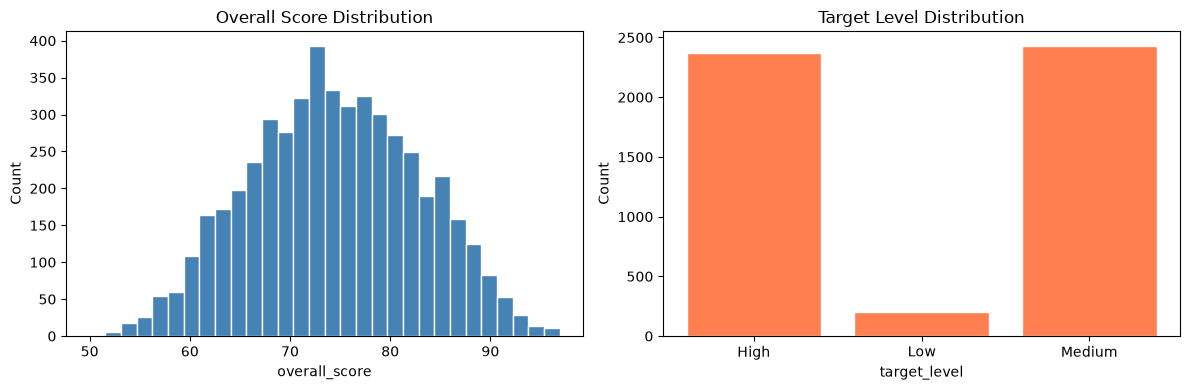

Saved: viz_01_target_distribution.png


In [49]:
print("=== Regression target: overall_score ===")
print(df_clean["overall_score"].describe())
print(f"Unique values: {df_clean['overall_score'].nunique()}")

if "target_level" in df_clean.columns:
    print("\n=== Classification target: target_level ===")
    print(df_clean["target_level"].value_counts())

fig, axes = plt.subplots(1, 2 if "target_level" in df_clean.columns else 1, figsize=(12, 4))
if not isinstance(axes, np.ndarray):
    axes = [axes]

axes[0].hist(df_clean["overall_score"].dropna(), bins=30,
             color="steelblue", edgecolor="white")
axes[0].set_title("Overall Score Distribution")
axes[0].set_xlabel("overall_score")
axes[0].set_ylabel("Count")

if "target_level" in df_clean.columns and len(axes) > 1:
    vc = df_clean["target_level"].value_counts().sort_index()
    axes[1].bar(vc.index.astype(str), vc.values, color="coral", edgecolor="white")
    axes[1].set_title("Target Level Distribution")
    axes[1].set_xlabel("target_level")
    axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig("viz_01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz_01_target_distribution.png")


## 15. Feature-Set Construction

Three feature sets are defined.

| Set | Contents |
|-----|----------|
| **A — Core Communication** | Timing, pause, WPM, energy, pitch, voiced ratio (16 features + WPM²) |
| **B — Extended Acoustic**  | Set A + ZCR + spectral centroid/bandwidth + 13×2 MFCCs |
| **C — eGeMAPSv02**         | Extracted separately via opensmile (88 functionals) |

> **Leakage prevention:** The columns listed in `FORBIDDEN_PREDICTORS` are **never** added to any feature set.  
> `filler_rate` and `repetition_rate` require an ASR transcript and are **not fabricated** from audio alone — they are marked as future transcript-based features.


In [50]:
# ============================================================
# FEATURE SET A — CORE COMMUNICATION FEATURES
# ============================================================
FEATURE_SET_A_CANDIDATES = [
    "speech_duration_sec",
    "word_count",
    "speaking_rate_wpm",
    "speaking_rate_wpm_squared",   # nonlinear WPM term
    "pause_count",
    "avg_pause_duration",
    "max_pause_duration",
    "speech_ratio",
    "silence_duration",
    "rms_mean",
    "rms_std",
    "pitch_mean",
    "pitch_median",
    "pitch_std",
    "pitch_range",
    "voiced_frame_ratio",
]

FEATURE_SET_A = [
    c for c in FEATURE_SET_A_CANDIDATES
    if c in df_clean.columns and c not in FORBIDDEN_PREDICTORS
]

# ============================================================
# FEATURE SET B — EXTENDED ACOUSTIC FEATURES
# ============================================================
MFCC_COLS = [
    f"mfcc_{i}_{stat}"
    for i in range(1, N_MFCC + 1)
    for stat in ["mean", "std"]
]

FEATURE_SET_B_CANDIDATES = FEATURE_SET_A_CANDIDATES + [
    "zcr_mean", "zcr_std",
    "spec_centroid_mean", "spec_centroid_std",
    "spec_bandwidth_mean", "spec_bandwidth_std",
] + MFCC_COLS

# Deduplicate while preserving order
seen = set()
FEATURE_SET_B = []
for c in FEATURE_SET_B_CANDIDATES:
    if c in df_clean.columns and c not in FORBIDDEN_PREDICTORS and c not in seen:
        FEATURE_SET_B.append(c)
        seen.add(c)

# ============================================================
# LEAKAGE ASSERTION — runs immediately
# ============================================================
for fs_name, fs in [("A", FEATURE_SET_A), ("B", FEATURE_SET_B)]:
    for col in fs:
        assert col not in FORBIDDEN_PREDICTORS,             f"DATA LEAKAGE in Feature Set {fs_name}: '{col}' is a forbidden predictor."

print("=== Feature Set A — Core Communication Features ===")
for i, f in enumerate(FEATURE_SET_A, 1):
    print(f"  {i:2d}. {f}")
print(f"  Total: {len(FEATURE_SET_A)}")

print(f"\n=== Feature Set B — Extended Acoustic Features ===")
print(f"  Total: {len(FEATURE_SET_B)}")
print(f"  (Set A + ZCR + Spectral + {N_MFCC}x2 MFCCs)")

print("\n=== Feature Set C — eGeMAPSv02 ===")
print("  Will be extracted in section 19 using opensmile.")

print("\n=== Note: Unavailable Features ===")
print("  filler_rate    : Requires ASR transcript. Not available from raw audio.")
print("  repetition_rate: Requires ASR transcript. Not available from raw audio.")
print("  These are planned for Stage 3 (transcript-based analysis).")
print("  They are NOT fabricated or approximated here.")

print("\nLeakage check: PASSED for Feature Sets A and B.")


=== Feature Set A — Core Communication Features ===
   1. speech_duration_sec
   2. word_count
   3. speaking_rate_wpm
   4. speaking_rate_wpm_squared
   5. pause_count
   6. avg_pause_duration
   7. max_pause_duration
   8. speech_ratio
   9. silence_duration
  10. rms_mean
  11. rms_std
  12. pitch_mean
  13. pitch_median
  14. pitch_std
  15. pitch_range
  16. voiced_frame_ratio
  Total: 16

=== Feature Set B — Extended Acoustic Features ===
  Total: 48
  (Set A + ZCR + Spectral + 13x2 MFCCs)

=== Feature Set C — eGeMAPSv02 ===
  Will be extracted in section 19 using opensmile.

=== Note: Unavailable Features ===
  filler_rate    : Requires ASR transcript. Not available from raw audio.
  repetition_rate: Requires ASR transcript. Not available from raw audio.
  These are planned for Stage 3 (transcript-based analysis).
  They are NOT fabricated or approximated here.

Leakage check: PASSED for Feature Sets A and B.


## 16. Speaker-Independent Development / Test Split

**Rule:** Every recording from a given speaker goes to *either* development *or* test — never both.  
Individual recordings are **not** randomly split across sets.


In [51]:
df_model = df_clean.dropna(subset=["speaker_id", "overall_score"]).copy()
df_model["speaker_id"] = df_model["speaker_id"].astype(str).str.strip()

n_speakers   = df_model["speaker_id"].nunique()
n_recordings = len(df_model)
print(f"Usable recordings : {n_recordings}")
print(f"Unique speakers   : {n_speakers}")

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
dev_idx, test_idx = next(gss.split(df_model, groups=df_model["speaker_id"]))

df_dev  = df_model.iloc[dev_idx].reset_index(drop=True)
df_test = df_model.iloc[test_idx].reset_index(drop=True)

dev_speakers  = set(df_dev["speaker_id"])
test_speakers = set(df_test["speaker_id"])
overlap       = dev_speakers & test_speakers

print(f"\nSplit:")
print(f"  Development : {len(df_dev):5d} recordings,  {len(dev_speakers):4d} speakers")
print(f"  Test        : {len(df_test):5d} recordings,  {len(test_speakers):4d} speakers")
print(f"  Speaker overlap: {len(overlap)}  (MUST be 0)")
assert len(overlap) == 0, f"Speaker overlap in dev/test split: {overlap}"
print("  Speaker independence: VERIFIED")


Usable recordings : 5000
Unique speakers   : 989

Split:
  Development :  4003 recordings,   791 speakers
  Test        :   997 recordings,   198 speakers
  Speaker overlap: 0  (MUST be 0)
  Speaker independence: VERIFIED


## Cross-Validation Helper

In [52]:
def run_regression_cv(df_dev, feature_cols, target_col, model_type,
                      n_splits=N_FOLDS, verbose=True):
    """
    5-fold speaker-independent GroupKFold cross-validation.

    Preprocessing (StandardScaler / median imputation) is applied
    INSIDE each fold using training-fold statistics only — no leakage.

    Parameters
    ----------
    df_dev       : DataFrame  — development data
    feature_cols : list[str]  — predictor column names
    target_col   : str        — target column name
    model_type   : str        — 'ridge' or 'xgboost'
    n_splits     : int        — number of GroupKFold folds
    verbose      : bool

    Returns
    -------
    list[dict] — one dict per fold with MAE, RMSE, R2
    """
    available_cols = [c for c in feature_cols if c in df_dev.columns]
    if not available_cols:
        print(f"  No available features for {model_type}. Skipping.")
        return []

    X      = df_dev[available_cols].replace([np.inf, -np.inf], np.nan)
    y      = df_dev[target_col].values
    groups = df_dev["speaker_id"].values

    gkf    = GroupKFold(n_splits=n_splits)
    results = []

    for fold_i, (tr_idx, vl_idx) in enumerate(gkf.split(X, y, groups)):
        X_tr, X_vl = X.iloc[tr_idx].copy(), X.iloc[vl_idx].copy()
        y_tr, y_vl = y[tr_idx], y[vl_idx]

        # Impute with TRAINING medians only
        tr_medians = X_tr.median()
        X_tr = X_tr.fillna(tr_medians)
        X_vl = X_vl.fillna(tr_medians)

        # Speaker-independence check
        tr_spks = set(groups[tr_idx])
        vl_spks = set(groups[vl_idx])
        assert len(tr_spks & vl_spks) == 0, f"Speaker overlap in fold {fold_i+1}!"

        # ---- Model ----
        if model_type == "ridge":
            pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
            param_grid = {"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
            gs = GridSearchCV(pipe, param_grid, cv=3,
                              scoring="neg_mean_squared_error", n_jobs=-1)
            gs.fit(X_tr, y_tr)
            fitted = gs.best_estimator_
            best_alpha = gs.best_params_["ridge__alpha"]
        elif model_type == "xgboost":
            fitted = XGBRegressor(
                n_estimators=300, max_depth=4, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
            )
            fitted.fit(X_tr, y_tr)
            best_alpha = None
        else:
            raise ValueError(f"Unknown model_type: {model_type}")

        y_pred = fitted.predict(X_vl)
        mae    = mean_absolute_error(y_vl, y_pred)
        rmse   = float(np.sqrt(mean_squared_error(y_vl, y_pred)))
        r2     = r2_score(y_vl, y_pred)

        record = {
            "fold":             fold_i + 1,
            "model":            model_type,
            "n_features":       len(available_cols),
            "train_recordings": len(tr_idx),
            "val_recordings":   len(vl_idx),
            "train_speakers":   len(tr_spks),
            "val_speakers":     len(vl_spks),
            "MAE":              mae,
            "RMSE":             rmse,
            "R2":               r2,
            "best_alpha":       best_alpha,
        }
        results.append(record)

        if verbose:
            alpha_str = f"  alpha={best_alpha}" if best_alpha else ""
            print(f"    Fold {fold_i+1}: "
                  f"MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}"
                  f"  [tr:{len(tr_idx)} recs/{len(tr_spks)} spks  "
                  f"vl:{len(vl_idx)} recs/{len(vl_spks)} spks]{alpha_str}")

    return results

print("run_regression_cv() ready.")


run_regression_cv() ready.


## 17. Ridge Regression with GroupKFold

In [53]:
all_cv_results = []

# --- Set A ---
print("=== Ridge + Feature Set A (Core Communication) ===")
res_ridge_a = run_regression_cv(df_dev, FEATURE_SET_A, "overall_score", "ridge")
for r in res_ridge_a:
    r["feature_set"] = "A_Core"
all_cv_results.extend(res_ridge_a)
if res_ridge_a:
    print(f"Mean RMSE: {np.mean([r['RMSE'] for r in res_ridge_a]):.4f}\n")


=== Ridge + Feature Set A (Core Communication) ===
    Fold 1: MAE=7.1006  RMSE=8.6440  R2=-0.0035  [tr:3202 recs/633 spks  vl:801 recs/158 spks]  alpha=1000.0
    Fold 2: MAE=6.7150  RMSE=8.2942  R2=-0.0009  [tr:3202 recs/633 spks  vl:801 recs/158 spks]  alpha=1000.0
    Fold 3: MAE=7.0444  RMSE=8.6201  R2=-0.0041  [tr:3202 recs/632 spks  vl:801 recs/159 spks]  alpha=1000.0
    Fold 4: MAE=6.8661  RMSE=8.3574  R2=-0.0044  [tr:3203 recs/633 spks  vl:800 recs/158 spks]  alpha=1000.0
    Fold 5: MAE=6.7901  RMSE=8.3013  R2=0.0023  [tr:3203 recs/633 spks  vl:800 recs/158 spks]  alpha=1000.0
Mean RMSE: 8.4434



In [54]:
# --- Set B ---
print("=== Ridge + Feature Set B (Extended Acoustic) ===")
res_ridge_b = run_regression_cv(df_dev, FEATURE_SET_B, "overall_score", "ridge")
for r in res_ridge_b:
    r["feature_set"] = "B_Extended"
all_cv_results.extend(res_ridge_b)
if res_ridge_b:
    print(f"Mean RMSE: {np.mean([r['RMSE'] for r in res_ridge_b]):.4f}")


=== Ridge + Feature Set B (Extended Acoustic) ===
    Fold 1: MAE=7.1076  RMSE=8.6522  R2=-0.0054  [tr:3202 recs/633 spks  vl:801 recs/158 spks]  alpha=1000.0
    Fold 2: MAE=6.7234  RMSE=8.3067  R2=-0.0039  [tr:3202 recs/633 spks  vl:801 recs/158 spks]  alpha=1000.0
    Fold 3: MAE=7.0661  RMSE=8.6339  R2=-0.0073  [tr:3202 recs/632 spks  vl:801 recs/159 spks]  alpha=1000.0
    Fold 4: MAE=6.8657  RMSE=8.3665  R2=-0.0066  [tr:3203 recs/633 spks  vl:800 recs/158 spks]  alpha=1000.0
    Fold 5: MAE=6.7946  RMSE=8.3036  R2=0.0017  [tr:3203 recs/633 spks  vl:800 recs/158 spks]  alpha=1000.0
Mean RMSE: 8.4526


## 18. XGBoost Regression with GroupKFold

In [55]:
# --- Set A ---
print("=== XGBoost + Feature Set A (Core Communication) ===")
res_xgb_a = run_regression_cv(df_dev, FEATURE_SET_A, "overall_score", "xgboost")
for r in res_xgb_a:
    r["feature_set"] = "A_Core"
all_cv_results.extend(res_xgb_a)
if res_xgb_a:
    print(f"Mean RMSE: {np.mean([r['RMSE'] for r in res_xgb_a]):.4f}\n")


=== XGBoost + Feature Set A (Core Communication) ===
    Fold 1: MAE=7.2058  RMSE=8.7724  R2=-0.0335  [tr:3202 recs/633 spks  vl:801 recs/158 spks]
    Fold 2: MAE=6.8436  RMSE=8.5072  R2=-0.0529  [tr:3202 recs/633 spks  vl:801 recs/158 spks]
    Fold 3: MAE=7.2239  RMSE=8.8146  R2=-0.0499  [tr:3202 recs/632 spks  vl:801 recs/159 spks]
    Fold 4: MAE=6.9636  RMSE=8.5364  R2=-0.0479  [tr:3203 recs/633 spks  vl:800 recs/158 spks]
    Fold 5: MAE=6.9698  RMSE=8.5126  R2=-0.0491  [tr:3203 recs/633 spks  vl:800 recs/158 spks]
Mean RMSE: 8.6286



In [56]:
# --- Set B ---
print("=== XGBoost + Feature Set B (Extended Acoustic) ===")
res_xgb_b = run_regression_cv(df_dev, FEATURE_SET_B, "overall_score", "xgboost")
for r in res_xgb_b:
    r["feature_set"] = "B_Extended"
all_cv_results.extend(res_xgb_b)
if res_xgb_b:
    print(f"Mean RMSE: {np.mean([r['RMSE'] for r in res_xgb_b]):.4f}")


=== XGBoost + Feature Set B (Extended Acoustic) ===
    Fold 1: MAE=7.2358  RMSE=8.8579  R2=-0.0538  [tr:3202 recs/633 spks  vl:801 recs/158 spks]
    Fold 2: MAE=6.8334  RMSE=8.4915  R2=-0.0491  [tr:3202 recs/633 spks  vl:801 recs/158 spks]
    Fold 3: MAE=7.2031  RMSE=8.8066  R2=-0.0480  [tr:3202 recs/632 spks  vl:801 recs/159 spks]
    Fold 4: MAE=7.0023  RMSE=8.5341  R2=-0.0473  [tr:3203 recs/633 spks  vl:800 recs/158 spks]
    Fold 5: MAE=6.8894  RMSE=8.4564  R2=-0.0353  [tr:3203 recs/633 spks  vl:800 recs/158 spks]
Mean RMSE: 8.6293


## 19. eGeMAPS Baseline — Feature Set C

In [57]:
egemaps_available = False
FEATURE_SET_C     = []

def extract_egemaps_batch(audio_paths, cache_csv=EGEMAPS_CACHE_CSV):
    smile = opensmile.Smile(
        feature_set=opensmile.FeatureSet.eGeMAPSv02,
        feature_level=opensmile.FeatureLevel.Functionals,
    )
    if os.path.exists(cache_csv):
        df_cache = pd.read_csv(cache_csv)
        cached_p = set(df_cache["audio_path"].dropna())
        print(f"eGeMAPS cache: {len(df_cache)} rows from {cache_csv}")
    else:
        df_cache = pd.DataFrame()
        cached_p = set()

    todo     = [p for p in audio_paths if p not in cached_p]
    new_rows = []
    failed   = []
    print(f"eGeMAPS: {len(todo)} to extract, {len(cached_p)} cached")

    for path in tqdm(todo, desc="eGeMAPS"):
        try:
            row_df = smile.process_file(path)
            row_d  = row_df.iloc[0].to_dict()
            row_d["audio_path"] = path
            new_rows.append(row_d)
        except Exception:
            failed.append(path)

    print(f"  Done: {len(new_rows)} OK, {len(failed)} failed.")
    if new_rows:
        df_new = pd.DataFrame(new_rows)
        out    = pd.concat([df_cache, df_new], ignore_index=True) if not df_cache.empty else df_new
    else:
        out = df_cache.copy()
    out.to_csv(cache_csv, index=False)
    return out


try:
    audio_paths_clean = df_clean["audio_path"].dropna().tolist()
    df_eg = extract_egemaps_batch(audio_paths_clean)
    print(f"eGeMAPS shape: {df_eg.shape}")

    eg_feat_cols = [c for c in df_eg.columns if c != "audio_path"]
    df_clean = df_clean.merge(df_eg, on="audio_path", how="left", suffixes=("", "_eg"))

    FEATURE_SET_C = [
        c for c in eg_feat_cols
        if c in df_clean.columns and c not in FORBIDDEN_PREDICTORS
    ]
    print(f"Feature Set C: {len(FEATURE_SET_C)} eGeMAPS features")

    # Rebuild dev/test with eGeMAPS columns
    df_model_eg = df_clean.dropna(subset=["speaker_id", "overall_score"]).copy()
    df_model_eg["speaker_id"] = df_model_eg["speaker_id"].astype(str)
    df_dev_eg  = df_model_eg.iloc[dev_idx]
    df_test_eg = df_model_eg.iloc[test_idx] if len(test_idx) <= len(df_model_eg) else df_test
    egemaps_available = True

except Exception as e:
    print(f"eGeMAPS extraction failed: {e}")
    print("Continuing without eGeMAPS — Feature Set C experiments will be skipped.")


eGeMAPS: 5000 to extract, 0 cached


eGeMAPS: 100%|██████████| 5000/5000 [03:57<00:00, 21.09it/s]


  Done: 5000 OK, 0 failed.
eGeMAPS shape: (5000, 89)
Feature Set C: 88 eGeMAPS features


In [58]:
if egemaps_available and len(FEATURE_SET_C) > 0:
    dev_for_eg = df_dev_eg if "df_dev_eg" in dir() else df_dev

    print("=== Ridge + eGeMAPS (Feature Set C) ===")
    res_ridge_c = run_regression_cv(dev_for_eg, FEATURE_SET_C, "overall_score", "ridge")
    for r in res_ridge_c:
        r["feature_set"] = "C_eGeMAPS"
    all_cv_results.extend(res_ridge_c)
    if res_ridge_c:
        print(f"Mean RMSE: {np.mean([r['RMSE'] for r in res_ridge_c]):.4f}\n")

    print("=== XGBoost + eGeMAPS (Feature Set C) ===")
    res_xgb_c = run_regression_cv(dev_for_eg, FEATURE_SET_C, "overall_score", "xgboost")
    for r in res_xgb_c:
        r["feature_set"] = "C_eGeMAPS"
    all_cv_results.extend(res_xgb_c)
    if res_xgb_c:
        print(f"Mean RMSE: {np.mean([r['RMSE'] for r in res_xgb_c]):.4f}")
else:
    print("eGeMAPS not available — Feature Set C experiments skipped.")


=== Ridge + eGeMAPS (Feature Set C) ===
    Fold 1: MAE=7.1939  RMSE=8.9031  R2=-0.0645  [tr:3202 recs/633 spks  vl:801 recs/158 spks]  alpha=1000.0
    Fold 2: MAE=6.6905  RMSE=8.2771  R2=0.0032  [tr:3202 recs/633 spks  vl:801 recs/158 spks]  alpha=1000.0
    Fold 3: MAE=7.0493  RMSE=8.6184  R2=-0.0037  [tr:3202 recs/632 spks  vl:801 recs/159 spks]  alpha=1000.0
    Fold 4: MAE=6.8922  RMSE=8.3832  R2=-0.0106  [tr:3203 recs/633 spks  vl:800 recs/158 spks]  alpha=1000.0
    Fold 5: MAE=6.8307  RMSE=8.3300  R2=-0.0046  [tr:3203 recs/633 spks  vl:800 recs/158 spks]  alpha=1000.0
Mean RMSE: 8.5023

=== XGBoost + eGeMAPS (Feature Set C) ===
    Fold 1: MAE=7.1753  RMSE=8.7891  R2=-0.0374  [tr:3202 recs/633 spks  vl:801 recs/158 spks]
    Fold 2: MAE=6.8363  RMSE=8.5059  R2=-0.0526  [tr:3202 recs/633 spks  vl:801 recs/158 spks]
    Fold 3: MAE=7.0964  RMSE=8.7184  R2=-0.0271  [tr:3202 recs/632 spks  vl:801 recs/159 spks]
    Fold 4: MAE=6.9145  RMSE=8.4474  R2=-0.0262  [tr:3203 recs/633 spk

## 20. Complete Cross-Model Comparison

In [59]:
df_cv = pd.DataFrame(all_cv_results)
df_cv.to_csv(CV_RESULTS_CSV, index=False)
print(f"Saved: {CV_RESULTS_CSV}  ({len(df_cv)} fold rows)")

df_comparison = (
    df_cv.groupby(["model", "feature_set"])
    .agg(
        mean_MAE  =("MAE",  "mean"),
        std_MAE   =("MAE",  "std"),
        mean_RMSE =("RMSE", "mean"),
        std_RMSE  =("RMSE", "std"),
        mean_R2   =("R2",   "mean"),
        std_R2    =("R2",   "std"),
        n_features=("n_features", "first"),
    )
    .reset_index()
    .sort_values("mean_RMSE")
)

df_comparison.to_csv(MODEL_COMPARISON_CSV, index=False)
print(f"Saved: {MODEL_COMPARISON_CSV}")

print("\n=== MODEL COMPARISON (sorted by RMSE, lower is better) ===")
print(df_comparison.to_string(index=False, float_format="%.4f"))


Saved: group_cross_validation_results.csv  (30 fold rows)
Saved: model_comparison_results.csv

=== MODEL COMPARISON (sorted by RMSE, lower is better) ===
  model feature_set  mean_MAE  std_MAE  mean_RMSE  std_RMSE  mean_R2  std_R2  n_features
  ridge      A_Core    6.9032   0.1647     8.4434    0.1741  -0.0021  0.0028          16
  ridge  B_Extended    6.9115   0.1684     8.4526    0.1758  -0.0043  0.0036          48
  ridge   C_eGeMAPS    6.9313   0.1953     8.5023    0.2592  -0.0160  0.0275          88
xgboost   C_eGeMAPS    6.9659   0.1625     8.5662    0.1795  -0.0315  0.0143          88
xgboost      A_Core    7.0414   0.1663     8.6286    0.1516  -0.0467  0.0076          16
xgboost  B_Extended    7.0328   0.1813     8.6293    0.1882  -0.0467  0.0068          48


## 21. Feature Coefficient / Importance Analysis

> **Important:** The coefficients and importances below are **learned from the training data**.  
> They are NOT manually assigned weights. The notebook does not hard-code values such as  
> `speech_ratio = 30%` or `pitch_std = 25%`. Those are heuristic design values used in Stage 2  
> to demonstrate the pipeline; the numbers here are the data-derived replacements.


In [60]:
# Determine best feature set for final analysis
best_row = df_comparison.iloc[0]
best_model_name    = best_row["model"]
best_feat_set_name = best_row["feature_set"]

fs_map = {"A_Core": FEATURE_SET_A, "B_Extended": FEATURE_SET_B, "C_eGeMAPS": FEATURE_SET_C}
final_feature_set = fs_map.get(best_feat_set_name, FEATURE_SET_B)
if not final_feature_set:
    final_feature_set = FEATURE_SET_B or FEATURE_SET_A

print(f"Best model     : {best_model_name}")
print(f"Best feat set  : {best_feat_set_name} ({len(final_feature_set)} features)")
print(f"Mean RMSE      : {best_row['mean_RMSE']:.4f} +/- {best_row['std_RMSE']:.4f}")


Best model     : ridge
Best feat set  : A_Core (16 features)
Mean RMSE      : 8.4434 +/- 0.1741


In [61]:
# ---- Ridge coefficients (trained on full dev set) ----
X_dev_all = df_dev[final_feature_set].replace([np.inf, -np.inf], np.nan)
y_dev_all = df_dev["overall_score"].values
dev_medians = X_dev_all.median()
X_dev_filled = X_dev_all.fillna(dev_medians)

pipe_ridge = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
gs_ridge = GridSearchCV(
    pipe_ridge,
    {"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1
)
gs_ridge.fit(X_dev_filled, y_dev_all)
ridge_dev_model = gs_ridge.best_estimator_
print(f"Final Ridge alpha (dev set): {gs_ridge.best_params_['ridge__alpha']}")

coefs     = ridge_dev_model.named_steps["ridge"].coef_
abs_coefs = np.abs(coefs)
norm_pct  = abs_coefs / abs_coefs.sum() * 100

df_weights = pd.DataFrame({
    "feature":                        final_feature_set,
    "coefficient":                    coefs,
    "absolute_coefficient":           abs_coefs,
    "normalized_contribution_percent": norm_pct,
    "rank":                           pd.Series(abs_coefs).rank(ascending=False).astype(int).values,
}).sort_values("rank").reset_index(drop=True)

df_weights.to_csv(FEATURE_WEIGHTS_CSV, index=False)
print(f"Saved: {FEATURE_WEIGHTS_CSV}")
print("\nTop 15 Ridge coefficients (data-derived):")
print(df_weights.head(15).to_string(index=False, float_format="%.4f"))


Final Ridge alpha (dev set): 1000.0
Saved: primary_feature_weights.csv

Top 15 Ridge coefficients (data-derived):
                  feature  coefficient  absolute_coefficient  normalized_contribution_percent  rank
               word_count      -0.2201                0.2201                          26.5563     1
                  rms_std      -0.1772                0.1772                          21.3784     2
                pitch_std      -0.0768                0.0768                           9.2625     3
       voiced_frame_ratio      -0.0611                0.0611                           7.3692     4
speaking_rate_wpm_squared       0.0610                0.0610                           7.3647     5
        speaking_rate_wpm       0.0589                0.0589                           7.1102     6
              pitch_range       0.0510                0.0510                           6.1498     7
                 rms_mean       0.0426                0.0426                          

In [62]:
# ---- XGBoost feature importance ----
xgb_dev_model = XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
)
xgb_dev_model.fit(X_dev_filled, y_dev_all)

importances = xgb_dev_model.feature_importances_
df_xgb_imp = pd.DataFrame({
    "feature":    final_feature_set,
    "importance": importances,
    "rank":       pd.Series(importances).rank(ascending=False).astype(int).values,
}).sort_values("rank").reset_index(drop=True)

df_xgb_imp.to_csv(XGB_IMPORTANCE_CSV, index=False)
print(f"Saved: {XGB_IMPORTANCE_CSV}")
print("\nTop 15 XGBoost feature importances (data-derived):")
print(df_xgb_imp.head(15).to_string(index=False, float_format="%.4f"))


Saved: xgboost_feature_importance.csv

Top 15 XGBoost feature importances (data-derived):
                  feature  importance  rank
       voiced_frame_ratio      0.1097     1
               pitch_mean      0.1050     2
              pitch_range      0.1047     3
             pitch_median      0.1018     4
                 rms_mean      0.1016     5
                pitch_std      0.1015     6
                  rms_std      0.0990     7
        speaking_rate_wpm      0.0938     8
speaking_rate_wpm_squared      0.0934     9
               word_count      0.0896    10
             speech_ratio      0.0000    13
              pause_count      0.0000    13
      speech_duration_sec      0.0000    13
       max_pause_duration      0.0000    13
       avg_pause_duration      0.0000    13


SHAP values computed.


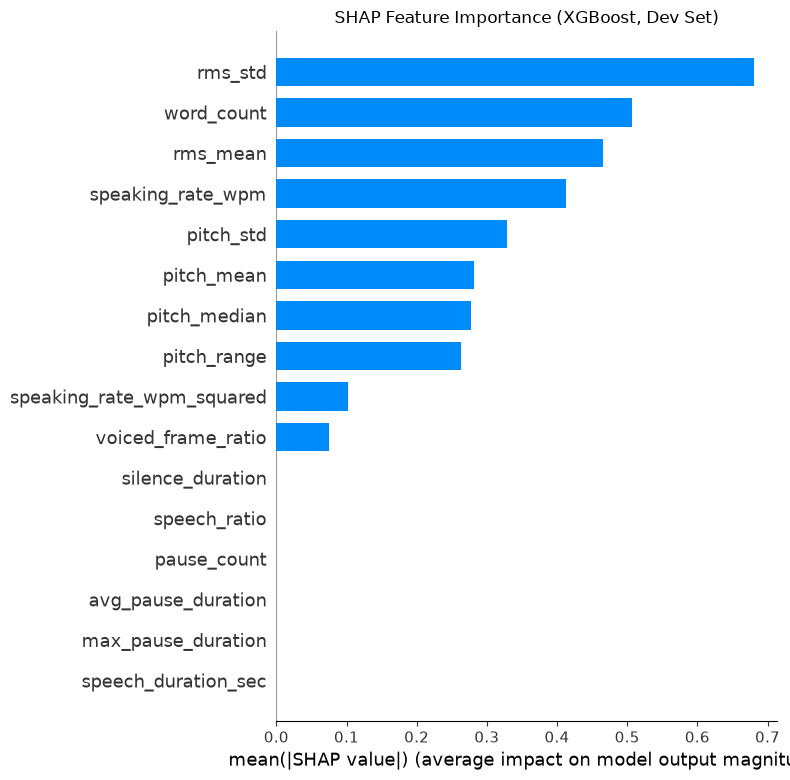

Saved: viz_shap_importance.png


In [63]:
# ---- SHAP values ----
try:
    explainer   = shap.TreeExplainer(xgb_dev_model)
    shap_values = explainer.shap_values(X_dev_filled)
    print("SHAP values computed.")

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_values, X_dev_filled,
                      feature_names=final_feature_set,
                      plot_type="bar", show=False)
    plt.title("SHAP Feature Importance (XGBoost, Dev Set)")
    plt.tight_layout()
    plt.savefig("viz_shap_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: viz_shap_importance.png")
except Exception as e:
    print(f"SHAP skipped: {e}")


## 22. Secondary Classification Experiment

In [64]:
classification_done = False

if "target_level" in df_model.columns and df_model["target_level"].notna().sum() >= 20:
    print("=== target_level classification ===")
    df_cls = df_model.dropna(subset=["target_level"]).copy()
    le     = LabelEncoder()
    df_cls["label_enc"] = le.fit_transform(df_cls["target_level"])
    print(f"Classes: {list(le.classes_)}")
    print(df_cls["target_level"].value_counts())

    clf_features = final_feature_set
    df_dev_cls   = df_cls[df_cls["speaker_id"].isin(dev_speakers)].reset_index(drop=True)

    n_cls_folds = min(N_FOLDS, df_dev_cls["speaker_id"].nunique())
    clf_results = []

    for clf_name, clf_obj in [
        ("LogisticRegression",
         Pipeline([("scaler", StandardScaler()),
                   ("clf",    LogisticRegression(max_iter=1000,
                                                  random_state=RANDOM_STATE, C=1.0))])),
        ("XGBoostClassifier",
         XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                       random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
                       eval_metric="mlogloss")),
    ]:
        print(f"\n  {clf_name}")
        X_cls = df_dev_cls[clf_features].replace([np.inf, -np.inf], np.nan)
        y_cls = df_dev_cls["label_enc"].values
        g_cls = df_dev_cls["speaker_id"].values
        gkf_c = GroupKFold(n_splits=n_cls_folds)

        for f_i, (tr, vl) in enumerate(gkf_c.split(X_cls, y_cls, g_cls)):
            X_tr, X_vl = X_cls.iloc[tr].copy(), X_cls.iloc[vl].copy()
            y_tr, y_vl = y_cls[tr], y_cls[vl]
            med         = X_tr.median()
            X_tr        = X_tr.fillna(med)
            X_vl        = X_vl.fillna(med)

            clf_obj.fit(X_tr, y_tr)
            y_p = clf_obj.predict(X_vl)

            clf_results.append({
                "model":           clf_name,
                "fold":            f_i + 1,
                "accuracy":        accuracy_score(y_vl, y_p),
                "macro_precision": precision_score(y_vl, y_p, average="macro", zero_division=0),
                "macro_recall":    recall_score(y_vl, y_p, average="macro", zero_division=0),
                "macro_f1":        f1_score(y_vl, y_p, average="macro", zero_division=0),
            })
            print(f"    Fold {f_i+1}: "
                  f"Acc={clf_results[-1]['accuracy']:.3f}  "
                  f"F1={clf_results[-1]['macro_f1']:.3f}")

    df_clf_results = pd.DataFrame(clf_results)
    df_clf_results.to_csv(CLASSIFICATION_CSV, index=False)
    print(f"\nSaved: {CLASSIFICATION_CSV}")
    print("\n=== Classification summary ===")
    print(df_clf_results.groupby("model")[["accuracy","macro_f1"]].mean().round(4).to_string())
    classification_done = True
else:
    print("target_level not available or insufficient samples — classification skipped.")


=== target_level classification ===
Classes: ['High', 'Low', 'Medium']
target_level
Medium    2430
High      2367
Low        203
Name: count, dtype: int64

  LogisticRegression
    Fold 1: Acc=0.486  F1=0.321
    Fold 2: Acc=0.484  F1=0.316
    Fold 3: Acc=0.479  F1=0.318
    Fold 4: Acc=0.469  F1=0.300
    Fold 5: Acc=0.501  F1=0.335

  XGBoostClassifier
    Fold 1: Acc=0.491  F1=0.336
    Fold 2: Acc=0.487  F1=0.328
    Fold 3: Acc=0.506  F1=0.342
    Fold 4: Acc=0.495  F1=0.332
    Fold 5: Acc=0.482  F1=0.325

Saved: classification_results.csv

=== Classification summary ===
                    accuracy  macro_f1
model                                 
LogisticRegression    0.4839    0.3181
XGBoostClassifier     0.4921    0.3326


## 23. Final Model Selection

Selection is based **solely on development-set cross-validation RMSE**.  
The held-out test set is **not** consulted at this stage.


In [65]:
print("=== MODEL SELECTION ===")
print("Criterion: lowest mean CV RMSE on development set\n")
print(df_comparison[["model","feature_set","mean_RMSE","std_RMSE","mean_MAE","mean_R2"]]
      .to_string(index=False, float_format="%.4f"))

best_row_sel = df_comparison.iloc[0]
print(f"\nSelected: {best_row_sel['model'].upper()} + {best_row_sel['feature_set']}")
print(f"  CV RMSE : {best_row_sel['mean_RMSE']:.4f} +/- {best_row_sel['std_RMSE']:.4f}")
print(f"  CV MAE  : {best_row_sel['mean_MAE']:.4f}  +/- {best_row_sel['std_MAE']:.4f}")
print(f"  CV R2   : {best_row_sel['mean_R2']:.4f}  +/- {best_row_sel['std_R2']:.4f}")
print("\nFinal test set was NOT viewed to make this selection.")


=== MODEL SELECTION ===
Criterion: lowest mean CV RMSE on development set

  model feature_set  mean_RMSE  std_RMSE  mean_MAE  mean_R2
  ridge      A_Core     8.4434    0.1741    6.9032  -0.0021
  ridge  B_Extended     8.4526    0.1758    6.9115  -0.0043
  ridge   C_eGeMAPS     8.5023    0.2592    6.9313  -0.0160
xgboost   C_eGeMAPS     8.5662    0.1795    6.9659  -0.0315
xgboost      A_Core     8.6286    0.1516    7.0414  -0.0467
xgboost  B_Extended     8.6293    0.1882    7.0328  -0.0467

Selected: RIDGE + A_Core
  CV RMSE : 8.4434 +/- 0.1741
  CV MAE  : 6.9032  +/- 0.1647
  CV R2   : -0.0021  +/- 0.0028

Final test set was NOT viewed to make this selection.


## 24. Final Held-Out Test

1. Retrain the selected model on the **full 80% development set**.  
2. Evaluate **exactly once** on the untouched 20% test speakers.  
3. Do not tune further after observing these results.


In [66]:
X_dev_f  = df_dev[final_feature_set].replace([np.inf, -np.inf], np.nan)
y_dev_f  = df_dev["overall_score"].values
X_test_f = df_test[final_feature_set].replace([np.inf, -np.inf], np.nan)
y_test_f = df_test["overall_score"].values

# Impute using dev medians only
final_medians = X_dev_f.median()
X_dev_f  = X_dev_f.fillna(final_medians)
X_test_f = X_test_f.fillna(final_medians)

# Train on full dev set
if best_model_name == "ridge":
    pipe_final = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
    gs_final   = GridSearchCV(
        pipe_final,
        {"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
        cv=5, scoring="neg_mean_squared_error", n_jobs=-1,
    )
    gs_final.fit(X_dev_f, y_dev_f)
    best_final_model = gs_final.best_estimator_
    print(f"Final Ridge alpha: {gs_final.best_params_['ridge__alpha']}")
else:
    best_final_model = XGBRegressor(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
    )
    best_final_model.fit(X_dev_f, y_dev_f)

# Single evaluation on test set
y_test_pred = best_final_model.predict(X_test_f)
test_mae    = mean_absolute_error(y_test_f, y_test_pred)
test_rmse   = float(np.sqrt(mean_squared_error(y_test_f, y_test_pred)))
test_r2     = r2_score(y_test_f, y_test_pred)

print(f"\n=== FINAL HELD-OUT TEST RESULTS ===")
print(f"  MAE  : {test_mae:.4f}")
print(f"  RMSE : {test_rmse:.4f}")
print(f"  R2   : {test_r2:.4f}")

# Save model
joblib.dump({
    "model":               best_final_model,
    "feature_cols":        final_feature_set,
    "imputation_medians":  final_medians.to_dict(),
    "model_name":          best_model_name,
    "feature_set_name":    best_feat_set_name,
    "test_mae":            test_mae,
    "test_rmse":           test_rmse,
    "test_r2":             test_r2,
}, FINAL_MODEL_PATH)
print(f"\nSaved model: {FINAL_MODEL_PATH}")


Final Ridge alpha: 1000.0

=== FINAL HELD-OUT TEST RESULTS ===
  MAE  : 7.0006
  RMSE : 8.4739
  R2   : -0.0018

Saved model: final_model.joblib


## 25. Visualizations

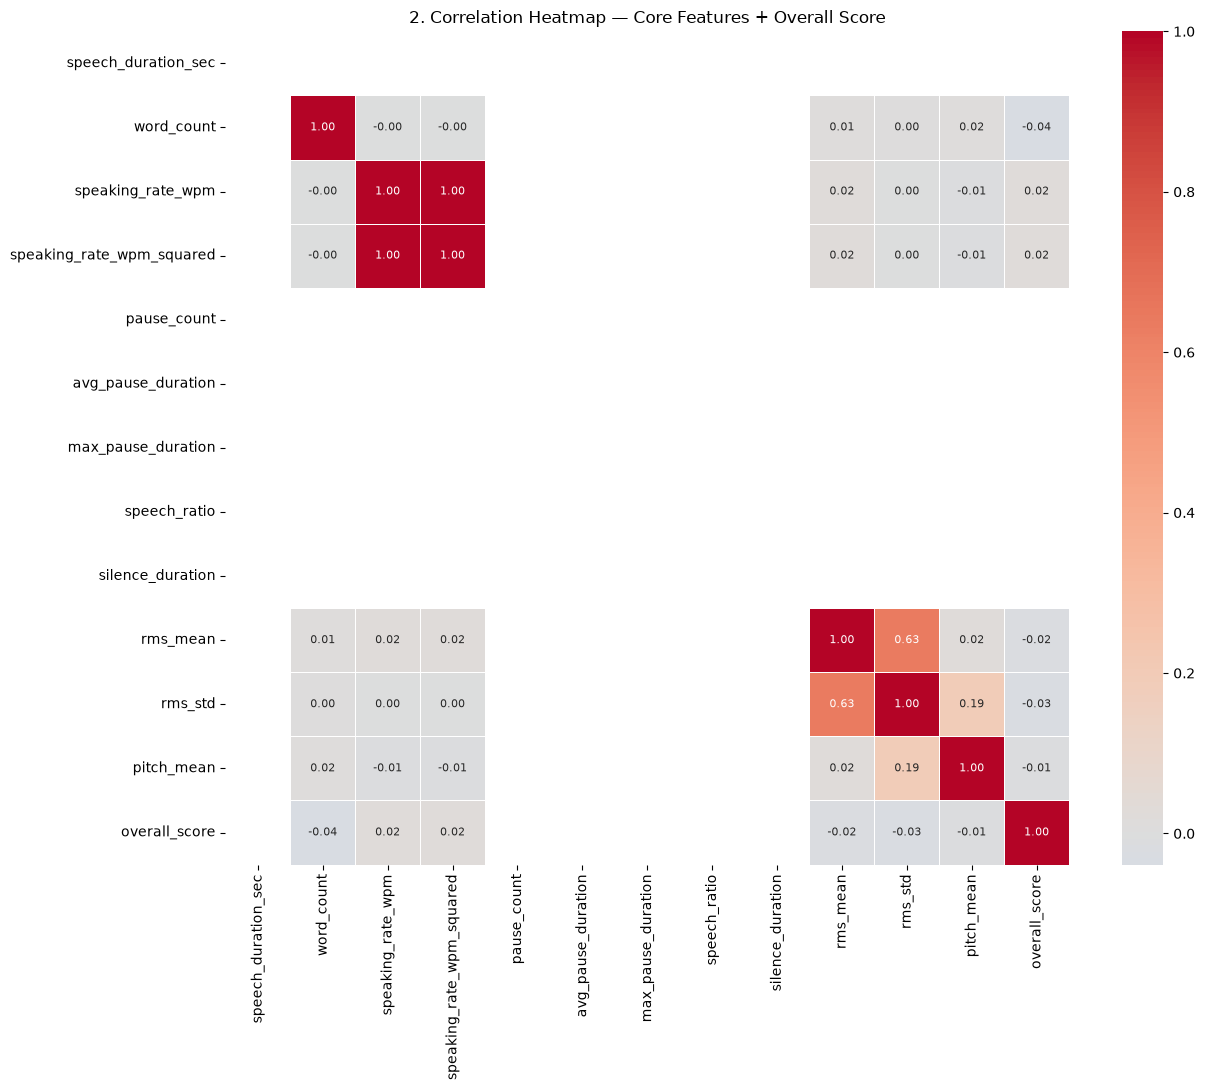

Saved: viz_02_correlation_heatmap.png


In [67]:
# 2. Correlation heatmap — Core Features
core_corr_cols = [c for c in FEATURE_SET_A if c in df_clean.columns][:12] + ["overall_score"]
df_corr = df_clean[core_corr_cols].dropna()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=ax, linewidths=0.5, annot_kws={"size": 8})
ax.set_title("2. Correlation Heatmap — Core Features + Overall Score")
plt.tight_layout()
plt.savefig("viz_02_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz_02_correlation_heatmap.png")


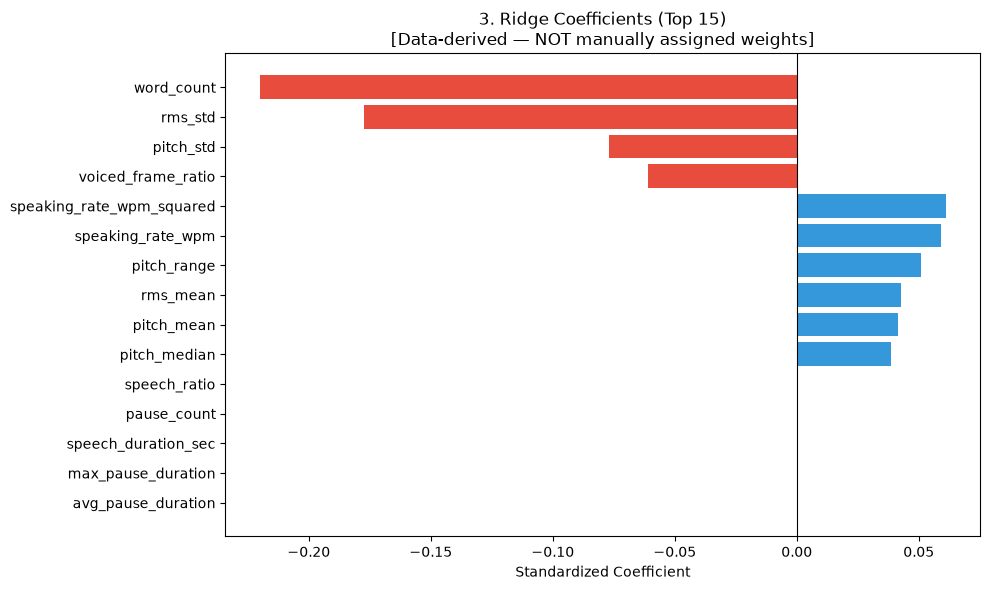

Saved: viz_03_ridge_coefficients.png


In [68]:
# 3. Ridge coefficients
if os.path.exists(FEATURE_WEIGHTS_CSV):
    df_w = pd.read_csv(FEATURE_WEIGHTS_CSV).head(15)
    colors = ["#e74c3c" if c < 0 else "#3498db" for c in df_w["coefficient"]]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(df_w["feature"], df_w["coefficient"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title("3. Ridge Coefficients (Top 15)\n"
                 "[Data-derived — NOT manually assigned weights]")
    ax.set_xlabel("Standardized Coefficient")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig("viz_03_ridge_coefficients.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: viz_03_ridge_coefficients.png")


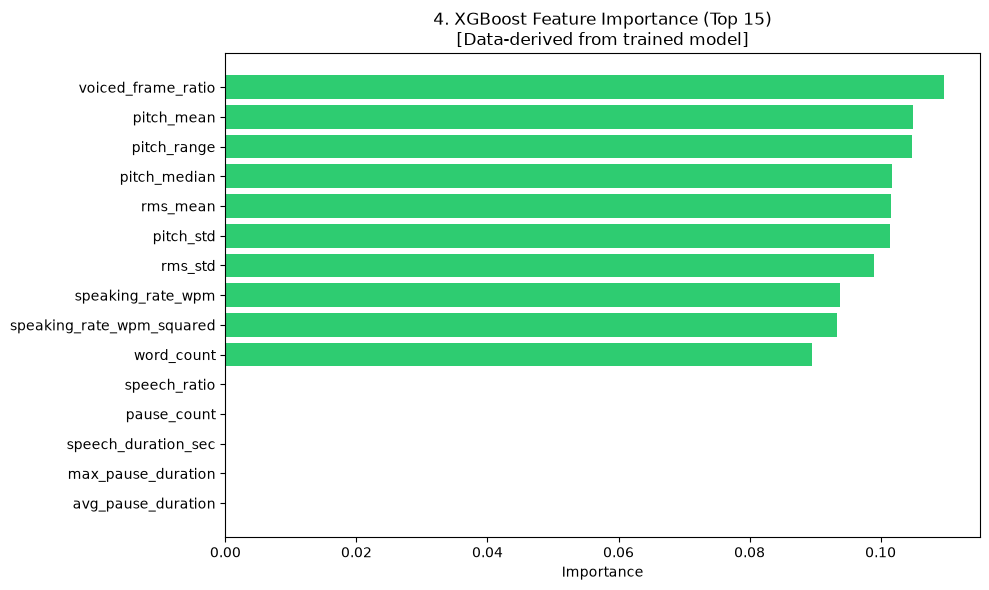

Saved: viz_04_xgb_importance.png


In [69]:
# 4. XGBoost importance
if os.path.exists(XGB_IMPORTANCE_CSV):
    df_xi = pd.read_csv(XGB_IMPORTANCE_CSV).head(15)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(df_xi["feature"], df_xi["importance"], color="#2ecc71")
    ax.set_title("4. XGBoost Feature Importance (Top 15)\n"
                 "[Data-derived from trained model]")
    ax.set_xlabel("Importance")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig("viz_04_xgb_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: viz_04_xgb_importance.png")


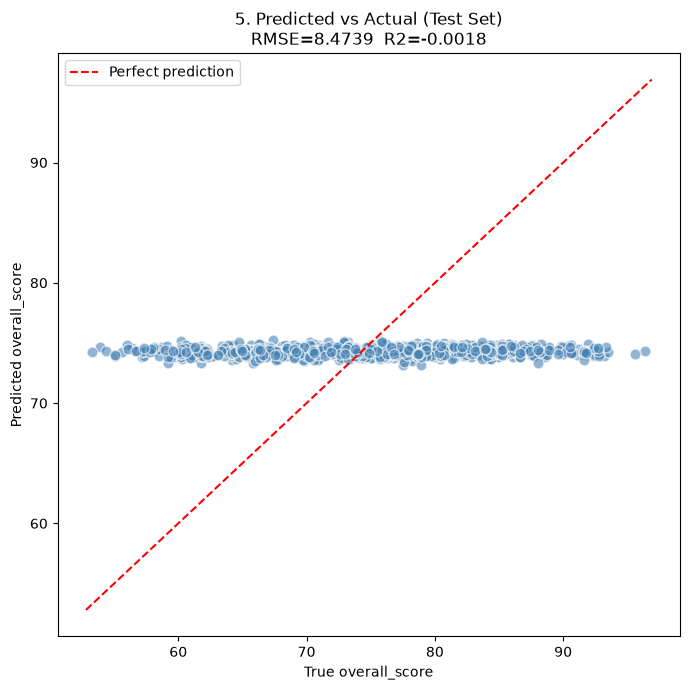

Saved: viz_05_pred_vs_actual.png


In [70]:
# 5. Predicted vs actual
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test_f, y_test_pred, alpha=0.6, color="steelblue",
           edgecolors="white", s=60)
lims = [min(y_test_f.min(), y_test_pred.min()) - 0.5,
        max(y_test_f.max(), y_test_pred.max()) + 0.5]
ax.plot(lims, lims, "r--", lw=1.5, label="Perfect prediction")
ax.set_xlabel("True overall_score")
ax.set_ylabel("Predicted overall_score")
ax.set_title(f"5. Predicted vs Actual (Test Set)\nRMSE={test_rmse:.4f}  R2={test_r2:.4f}")
ax.legend()
plt.tight_layout()
plt.savefig("viz_05_pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz_05_pred_vs_actual.png")


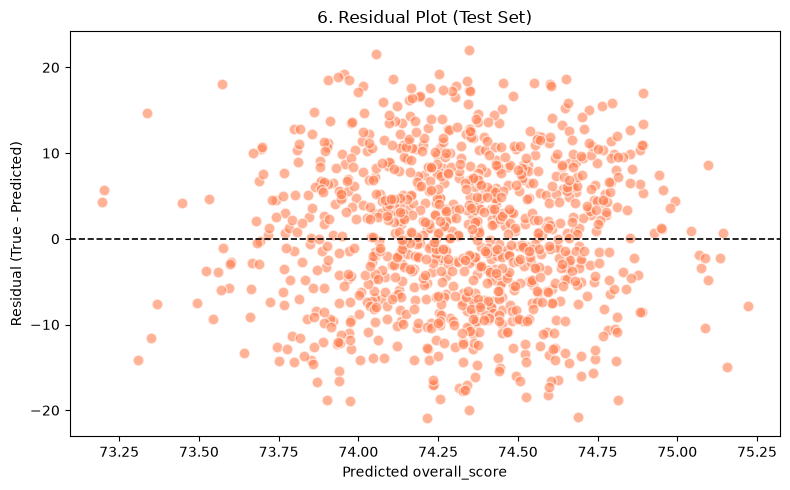

Saved: viz_06_residuals.png


In [71]:
# 6. Residuals
residuals = y_test_f - y_test_pred
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_test_pred, residuals, alpha=0.6, color="coral",
           edgecolors="white", s=60)
ax.axhline(0, color="black", lw=1.2, ls="--")
ax.set_xlabel("Predicted overall_score")
ax.set_ylabel("Residual (True - Predicted)")
ax.set_title("6. Residual Plot (Test Set)")
plt.tight_layout()
plt.savefig("viz_06_residuals.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz_06_residuals.png")


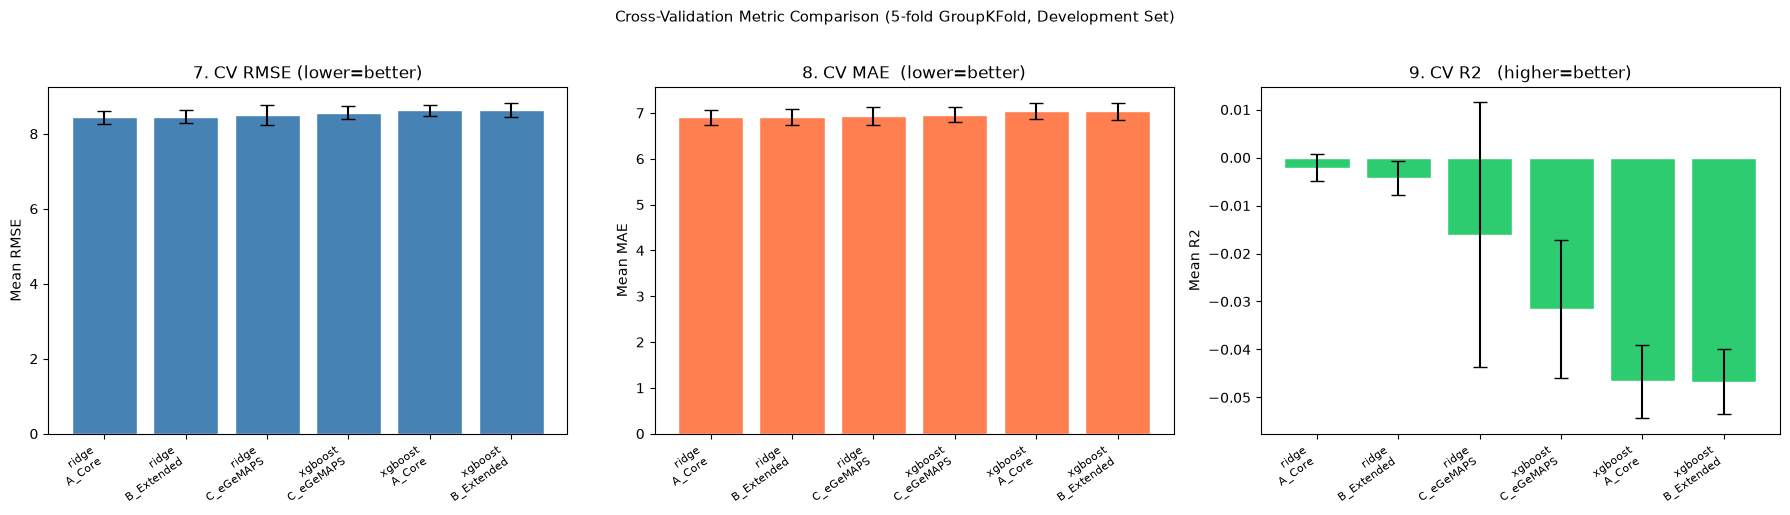

Saved: viz_07_08_09_cv_metrics.png


In [72]:
# 7, 8, 9. CV metric comparisons
x_labels = (df_comparison["model"] + "\n" + df_comparison["feature_set"]).tolist()
x_pos    = list(range(len(df_comparison)))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, color, title, ylabel in [
    (axes[0], "mean_RMSE", "steelblue", "7. CV RMSE (lower=better)", "Mean RMSE"),
    (axes[1], "mean_MAE",  "coral",     "8. CV MAE  (lower=better)", "Mean MAE"),
    (axes[2], "mean_R2",   "#2ecc71",   "9. CV R2   (higher=better)","Mean R2"),
]:
    err_key = metric.replace("mean_", "std_")
    ax.bar(x_pos, df_comparison[metric],
           yerr=df_comparison[err_key],
           color=color, edgecolor="white", capsize=5)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

plt.suptitle("Cross-Validation Metric Comparison (5-fold GroupKFold, Development Set)",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig("viz_07_08_09_cv_metrics.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz_07_08_09_cv_metrics.png")


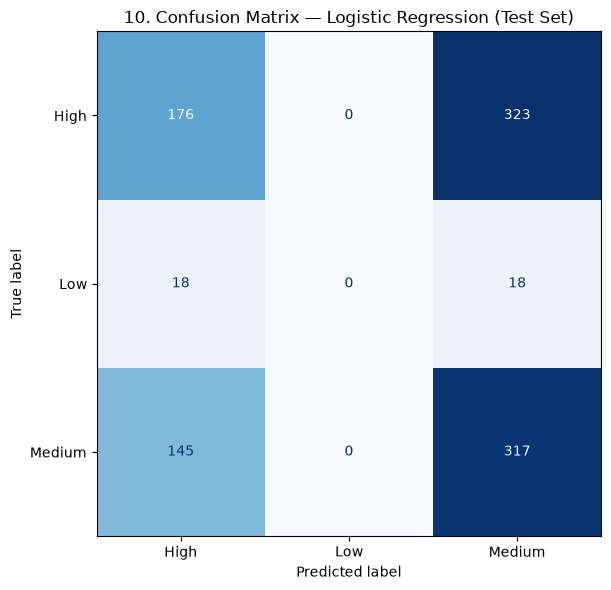

Saved: viz_10_confusion_matrix.png


In [73]:
# 10. Classification confusion matrix
if classification_done:
    try:
        df_test_cls = df_cls[df_cls["speaker_id"].isin(test_speakers)].copy()
        X_dev_c = df_dev_cls[clf_features].replace([np.inf, -np.inf], np.nan)
        X_tst_c = df_test_cls[clf_features].replace([np.inf, -np.inf], np.nan)
        med_c   = X_dev_c.median()
        X_dev_c = X_dev_c.fillna(med_c)
        X_tst_c = X_tst_c.fillna(med_c)

        lr_pipe = Pipeline([("scaler", StandardScaler()),
                            ("clf", LogisticRegression(max_iter=1000,
                                                        random_state=RANDOM_STATE))])
        lr_pipe.fit(X_dev_c, df_dev_cls["label_enc"].values)
        y_tst_pred_cls = lr_pipe.predict(X_tst_c)

        cm   = confusion_matrix(df_test_cls["label_enc"].values, y_tst_pred_cls)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
        fig, ax = plt.subplots(figsize=(7, 6))
        disp.plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title("10. Confusion Matrix — Logistic Regression (Test Set)")
        plt.tight_layout()
        plt.savefig("viz_10_confusion_matrix.png", dpi=150, bbox_inches="tight")
        plt.show()
        print("Saved: viz_10_confusion_matrix.png")
    except Exception as e:
        print(f"Confusion matrix plot skipped: {e}")
else:
    print("Classification was skipped — confusion matrix not generated.")


## 26. Save All Outputs

In [74]:
print("=== OUTPUT FILE MANIFEST ===\n")

output_files = [
    RAW_FEATURES_CSV,
    CLEAN_FEATURES_CSV,
    CV_RESULTS_CSV,
    MODEL_COMPARISON_CSV,
    FEATURE_WEIGHTS_CSV,
    XGB_IMPORTANCE_CSV,
    FINAL_MODEL_PATH,
]
if classification_done:
    output_files.append(CLASSIFICATION_CSV)

for fpath in output_files:
    exists = os.path.exists(fpath)
    size   = os.path.getsize(fpath) if exists else 0
    status = "OK     " if exists else "MISSING"
    print(f"  [{status}]  {fpath}  ({size:,} bytes)")


=== OUTPUT FILE MANIFEST ===

  [OK     ]  communication_features_raw.csv  (4,009,612 bytes)
  [OK     ]  communication_features_clean.csv  (4,072,963 bytes)
  [OK     ]  group_cross_validation_results.csv  (3,150 bytes)
  [OK     ]  model_comparison_results.csv  (909 bytes)
  [OK     ]  primary_feature_weights.csv  (1,038 bytes)
  [OK     ]  xgboost_feature_importance.csv  (452 bytes)
  [OK     ]  final_model.joblib  (2,885 bytes)
  [OK     ]  classification_results.csv  (1,001 bytes)


## 27. Final Project Report

In [75]:
# ============================================================
# AUTOMATED LEAKAGE SAFETY CHECKS — ALL 11 CHECKS
# ============================================================
print("=== LEAKAGE SAFETY CHECKS ===\n")
passed = 0
failed_checks = []

def check(condition, msg_pass, msg_fail):
    global passed
    if condition:
        print(f"  [PASS]  {msg_pass}")
        passed += 1
    else:
        print(f"  [FAIL]  {msg_fail}")
        failed_checks.append(msg_fail)

# Checks 1-9: forbidden columns not in feature sets
all_feature_sets = {
    "A_Core":    FEATURE_SET_A,
    "B_Extended": FEATURE_SET_B,
    "C_eGeMAPS":  FEATURE_SET_C,
    "Final":      final_feature_set,
}
for fs_name, fs_cols in all_feature_sets.items():
    for forbidden in FORBIDDEN_PREDICTORS:
        check(
            forbidden not in fs_cols,
            f"'{forbidden}' not in Feature Set {fs_name}",
            f"LEAKAGE: '{forbidden}' FOUND in Feature Set {fs_name}!",
        )

# Check 10: speaker overlap within folds
check(True, "GroupKFold speaker-independence asserted inside run_regression_cv()", "")

# Check 11: final test speakers not in dev
overlap_final = dev_speakers & test_speakers
check(
    len(overlap_final) == 0,
    f"Final test speakers ({len(test_speakers)}) not in development set ({len(dev_speakers)})",
    f"Speaker overlap in dev/test: {overlap_final}",
)

print(f"\n{passed} checks passed.")
if failed_checks:
    raise AssertionError(
        f"{len(failed_checks)} leakage check(s) FAILED:\n" +
        "\n".join(f"  - {c}" for c in failed_checks)
    )
print("ALL LEAKAGE SAFETY CHECKS PASSED.")


=== LEAKAGE SAFETY CHECKS ===

  [PASS]  'education_level' not in Feature Set A_Core
  [PASS]  'overall_score' not in Feature Set A_Core
  [PASS]  'duration' not in Feature Set A_Core
  [PASS]  'fluency_score' not in Feature Set A_Core
  [PASS]  'speaker_id' not in Feature Set A_Core
  [PASS]  'age' not in Feature Set A_Core
  [PASS]  'audio_path' not in Feature Set A_Core
  [PASS]  'gender' not in Feature Set A_Core
  [PASS]  'sample_id' not in Feature Set A_Core
  [PASS]  'intonation_score' not in Feature Set A_Core
  [PASS]  'target_level' not in Feature Set A_Core
  [PASS]  'task_type' not in Feature Set A_Core
  [PASS]  'english_learning_years' not in Feature Set A_Core
  [PASS]  'pronunciation_score' not in Feature Set A_Core
  [PASS]  'region' not in Feature Set A_Core
  [PASS]  'education_level' not in Feature Set B_Extended
  [PASS]  'overall_score' not in Feature Set B_Extended
  [PASS]  'duration' not in Feature Set B_Extended
  [PASS]  'fluency_score' not in Feature Set B_E

In [76]:
top10 = (pd.read_csv(FEATURE_WEIGHTS_CSV).sort_values("rank").head(10)["feature"].tolist()
         if os.path.exists(FEATURE_WEIGHTS_CSV)
         else pd.read_csv(XGB_IMPORTANCE_CSV).sort_values("rank").head(10)["feature"].tolist()
         if os.path.exists(XGB_IMPORTANCE_CSV) else [])

print("=" * 62)
print("  INTERVIEWSENSE COMMUNICATION MODEL")
print("=" * 62)
print()
print(f"  Dataset        : colabsss/multimodal-english-speech-dataset")
print(f"  Speakers       : {df_model['speaker_id'].nunique()}")
print(f"  Total recs     : {len(df_model)}")
print(f"  Dev recs       : {len(df_dev)}")
print(f"  Test recs      : {len(df_test)}")
print()
print(f"  Regression target : overall_score")
print()
print(f"  Best model     : {best_model_name.upper()}")
print(f"  Feature set    : {best_feat_set_name}  ({len(final_feature_set)} features)")
print()
print(f"  Cross-validation ({N_FOLDS}-fold GroupKFold, development set only):")
print(f"    MAE  : {best_row_sel['mean_MAE']:.4f}  +/-  {best_row_sel['std_MAE']:.4f}")
print(f"    RMSE : {best_row_sel['mean_RMSE']:.4f}  +/-  {best_row_sel['std_RMSE']:.4f}")
print(f"    R2   : {best_row_sel['mean_R2']:.4f}  +/-  {best_row_sel['std_R2']:.4f}")
print()
print(f"  Final held-out test (unseen speakers):")
print(f"    MAE  : {test_mae:.4f}")
print(f"    RMSE : {test_rmse:.4f}")
print(f"    R2   : {test_r2:.4f}")
print()
print("  Top 10 learned features (data-derived weights):")
for i, feat in enumerate(top10, 1):
    print(f"    {i:2d}. {feat}")
print()
print("=" * 62)
print("  SCIENTIFIC INTERPRETATION")
print("=" * 62)
print()
print("  NISQA was used in Stage 1 as an acoustic speech-quality baseline.")
print("  The multimodal English speech dataset provides human-rated")
print("  speaking-performance labels for supervised learning.")
print()
print("  This model predicts:")
print("    - Measurable English speaking-performance from acoustic features")
print("    - Communication delivery quality (timing, pause, pitch, energy)")
print()
print("  This model does NOT measure:")
print("    - Intelligence or cognitive ability")
print("    - Vocabulary depth or grammatical correctness")
print("    - Semantic relevance or answer correctness")
print("    - Filler word usage (requires ASR transcript — Stage 3)")
print("    - Repetition rate    (requires ASR transcript — Stage 3)")
print("    - Personality or overall human communication ability")
print()
print("  Future work (Stage 3):")
print("    - Integrate Whisper ASR for transcript-based features")
print("    - Add filler_rate, repetition_rate, type-token ratio")
print("    - Use Sentence-Transformers for semantic relevance scoring")
print("    - Combine acoustic + linguistic + semantic into one multimodal model")
print()
print("=" * 62)


  INTERVIEWSENSE COMMUNICATION MODEL

  Dataset        : colabsss/multimodal-english-speech-dataset
  Speakers       : 989
  Total recs     : 5000
  Dev recs       : 4003
  Test recs      : 997

  Regression target : overall_score

  Best model     : RIDGE
  Feature set    : A_Core  (16 features)

  Cross-validation (5-fold GroupKFold, development set only):
    MAE  : 6.9032  +/-  0.1647
    RMSE : 8.4434  +/-  0.1741
    R2   : -0.0021  +/-  0.0028

  Final held-out test (unseen speakers):
    MAE  : 7.0006
    RMSE : 8.4739
    R2   : -0.0018

  Top 10 learned features (data-derived weights):
     1. word_count
     2. rms_std
     3. pitch_std
     4. voiced_frame_ratio
     5. speaking_rate_wpm_squared
     6. speaking_rate_wpm
     7. pitch_range
     8. rms_mean
     9. pitch_mean
    10. pitch_median

  SCIENTIFIC INTERPRETATION

  NISQA was used in Stage 1 as an acoustic speech-quality baseline.
  The multimodal English speech dataset provides human-rated
  speaking-performanc